# Bayesian analysis of the minimal model — B± → K± K+ K−

Minimal six-parameter model (fit window $[5150,5450]$ MeV, Gaussian signal, one exponential background with a shape and a yield shared by the two charges), used in the report as a cross-check of the nominal model (section "A Minimal Model as Cross-Check"); the nominal model is in `Bayesian_Nominal.ipynb`. Same preselection and same parametrization of the signal yields as the frequentist analysis. The model (pdfs, priors, likelihood) is in `bayesian_model.py`.

**[Giacomo, 2026-10-07]** Notebook re-run top to bottom (2026-10-06/07, ~16 h on one core): the outputs and `results/posterior_summary.json` are up to date and match the minimal-model values quoted in the report. Compared with the first version, it includes: Gaussian approximation of the Bayes factor, fit with free background asymmetry, chains from dispersed starting points, charm vetoes, bias/spread of the toys, and Dalitz significance with respect to the global asymmetry.


In [1]:
import sys
import os
import json as _json
import numpy as np
import pandas as pd
import uproot
import matplotlib.pyplot as plt
import emcee
import corner
from scipy.stats import gaussian_kde

sys.path.insert(0, ".")
import bayesian_model as bm

np.random.seed(42)

# results dir up front (absolute path) + incremental checkpoint helper -- a late-cell failure
# after a long run must not wipe out everything computed before it (lesson learned 2026-09-22)
RESULTS_DIR = os.path.join(os.getcwd(), "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

def checkpoint_save(name, data):
    path = os.path.join(RESULTS_DIR, f"{name}.json")
    with open(path, "w") as f:
        _json.dump(data, f, indent=2, default=str)
    print(f"[checkpoint] saved {path}")

print("RESULTS_DIR =", RESULTS_DIR)

RESULTS_DIR = /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results


## Data and preselection

Shared preselection (from the official notebook): `H*_ProbPi < 0.5 & H*_ProbK > 0.5 & !H*_isMuon` on the three final-state hadrons.

In [2]:
DATA_DIR = "../../opendata-project/Data"
FILES = [f"{DATA_DIR}/B2HHH_MagnetDown.root", f"{DATA_DIR}/B2HHH_MagnetUp.root"]

BRANCHES = [f"H{i}_{v}" for i in (1, 2, 3)
            for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge")]

frames = []
for path in FILES:
    with uproot.open(path) as f:
        tree = f["DecayTree"]
        arrs = tree.arrays(BRANCHES, library="pd")
    arrs["magnet"] = "down" if "Down" in path else "up"
    frames.append(arrs)

data = pd.concat(frames, ignore_index=True)
print("total events read:", len(data))

total events read: 8556118


In [3]:
presel = (
    (data.H1_ProbPi < 0.5) & (data.H2_ProbPi < 0.5) & (data.H3_ProbPi < 0.5) &
    (data.H1_ProbK > 0.5) & (data.H2_ProbK > 0.5) & (data.H3_ProbK > 0.5) &
    (~data.H1_isMuon.astype(bool)) & (~data.H2_isMuon.astype(bool)) & (~data.H3_isMuon.astype(bool))
)
data = data[presel].reset_index(drop=True)
print(f"after preselection: {len(data)} ({100*presel.mean():.2f}% of read events)")

after preselection: 23895 (0.28% of read events)


## Invariant mass (KKK hypothesis) and fit window

Energies are computed with the kaon mass hypothesis ($M_K = 493.677$ MeV) and the B mass is reconstructed from the sum of the four-momenta. The fit window (`MASS_LO`, `MASS_HI` in `bayesian_model.py`) was chosen after looking at the data: below ~5150 MeV the background rises (probably partially reconstructed decays), which a single exponential does not describe; this minimal model excludes that region instead of using a more complex background model (the nominal model does the latter).

In [4]:
M_K = 493.677  # MeV/c^2

def track_energy(px, py, pz, mass):
    return np.sqrt(px**2 + py**2 + pz**2 + mass**2)

for i in (1, 2, 3):
    data[f"H{i}_E"] = track_energy(data[f"H{i}_PX"], data[f"H{i}_PY"], data[f"H{i}_PZ"], M_K)

B_PX = data.H1_PX + data.H2_PX + data.H3_PX
B_PY = data.H1_PY + data.H2_PY + data.H3_PY
B_PZ = data.H1_PZ + data.H2_PZ + data.H3_PZ
B_E = data.H1_E + data.H2_E + data.H3_E

data["B_M"] = np.sqrt(np.clip(B_E**2 - (B_PX**2 + B_PY**2 + B_PZ**2), 0, None))
data["B_Charge"] = data.H1_Charge + data.H2_Charge + data.H3_Charge

data = data[data.B_Charge.isin([1, -1])].reset_index(drop=True)
mask = (data.B_M > bm.MASS_LO) & (data.B_M < bm.MASS_HI)
data = data[mask].reset_index(drop=True)

m_obs = data.B_M.to_numpy()
q_obs = data.B_Charge.to_numpy()
magnet_obs = data.magnet.to_numpy()
print(f"events in fit window [{bm.MASS_LO}, {bm.MASS_HI}] MeV: {len(m_obs)}")
print(f"  B+ : {np.sum(q_obs > 0)}   B- : {np.sum(q_obs < 0)}")
print(f"  magnet down: {np.sum(magnet_obs == 'down')}   magnet up: {np.sum(magnet_obs == 'up')}")

events in fit window [5150.0, 5450.0] MeV: 17839
  B+ : 9358   B- : 8481
  magnet down: 10500   magnet up: 7339


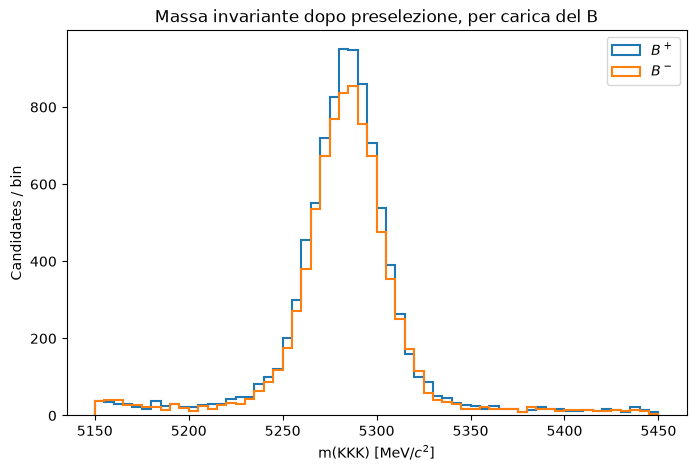

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.linspace(bm.MASS_LO, bm.MASS_HI, 61)
ax.hist(m_obs[q_obs > 0], bins=bins, histtype="step", label=r"$B^+$", linewidth=1.5)
ax.hist(m_obs[q_obs < 0], bins=bins, histtype="step", label=r"$B^-$", linewidth=1.5)
ax.set_xlabel("m(KKK) [MeV/$c^2$]")
ax.set_ylabel("Candidates / bin")
ax.legend()
ax.set_title("Massa invariante dopo preselezione, per carica del B")
plt.show()

## Mass model and likelihood

$f(m) = N_s\,S(m;\mu,\sigma) + N_b\,B(m;\lambda)$, simultaneous fit with $N_s^+ = N_s(1-A)/2$, $N_s^- = N_s(1+A)/2$ (background split equally between the charges, no background asymmetry). Signal = truncated Gaussian, background = truncated exponential, both normalized on $[\mathrm{MASS\_LO}, \mathrm{MASS\_HI}]$. Implementation in `bayesian_model.py` (`signal_pdf`, `background_pdf`, `log_likelihood`).

## Priors

Uniform priors with hard bounds (`0.0` inside, `-np.inf` outside). Bounds and starting point from a first look at the data (peak at ~5283 MeV, $N_s\approx 14300$, $N_b\approx 3550$ from a sideband vs signal-window estimate), see `bayesian_model.PRIOR_BOUNDS` / `INITIAL_GUESS`.

In [6]:
for name in bm.PARAM_NAMES:
    lo, hi = bm.PRIOR_BOUNDS[name]
    print(f"{name:12s} bounds=({lo:.4g}, {hi:.4g})  guess={bm.INITIAL_GUESS[name]:.4g}")

theta0 = np.array([bm.INITIAL_GUESS[n] for n in bm.PARAM_NAMES])
lp0 = bm.log_posterior(theta0, m_obs, q_obs)
print("\nlog_posterior at initial guess:", lp0)
assert np.isfinite(lp0), 'initial guess falls outside the prior or gives zero likelihood'

N_s          bounds=(0, 8.92e+04)  guess=1.43e+04
N_b          bounds=(0, 8.92e+04)  guess=3550
A            bounds=(-1, 1)  guess=0
mu           bounds=(5260, 5310)  guess=5283
sigma        bounds=(3, 40)  guess=15
lambda_bkg   bounds=(1e-05, 0.05)  guess=0.0028

log_posterior at initial guess: 59666.50939435986


## MCMC sampling (emcee)

Walkers initialized in a narrow ball around the starting point (the alternative, sampling the starting points uniformly over the prior box, is used below as a convergence check).

In [7]:
ndim = len(theta0)
nwalkers = 32
nsteps = 9000

spread = np.array([
    0.03 * theta0[0],  # N_s
    0.05 * theta0[1],  # N_b
    0.05,               # A
    1.0,                 # mu
    1.0,                 # sigma
    0.15 * theta0[5],   # lambda_bkg
])
pos = theta0 + spread * np.random.default_rng(42).standard_normal((nwalkers, ndim))
pos[:, 2] = np.clip(pos[:, 2], -0.5, 0.5)  # keep A inside a sane starting range

sampler = emcee.EnsembleSampler(nwalkers, ndim, bm.log_posterior, args=(m_obs, q_obs))
sampler.run_mcmc(pos, nsteps, progress=True)
print("mean acceptance fraction:", np.mean(sampler.acceptance_fraction))

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 8/9000 [00:00<02:00, 74.84it/s]

  0%|          | 16/9000 [00:00<02:00, 74.57it/s]

  0%|          | 24/9000 [00:00<02:00, 74.70it/s]

  0%|          | 32/9000 [00:00<02:17, 65.22it/s]

...

100%|█████████▉| 8988/9000 [17:46<00:00, 57.48it/s]

100%|█████████▉| 8994/9000 [17:46<00:00, 52.12it/s]

100%|██████████| 9000/9000 [17:46<00:00, 43.34it/s]

100%|██████████| 9000/9000 [17:46<00:00,  8.44it/s]

mean acceptance fraction: 0.5170868055555555


## Convergence diagnostics

Integrated autocorrelation time of each parameter and chain length in units of it.

autocorrelation time per parametro:
  N_s          tau=76.7  (n_eff ~= 3755)
  N_b          tau=79.2  (n_eff ~= 3636)
  A            tau=71.2  (n_eff ~= 4046)
  mu           tau=60.8  (n_eff ~= 4740)
  sigma        tau=58.4  (n_eff ~= 4932)
  lambda_bkg   tau=70.1  (n_eff ~= 4108)


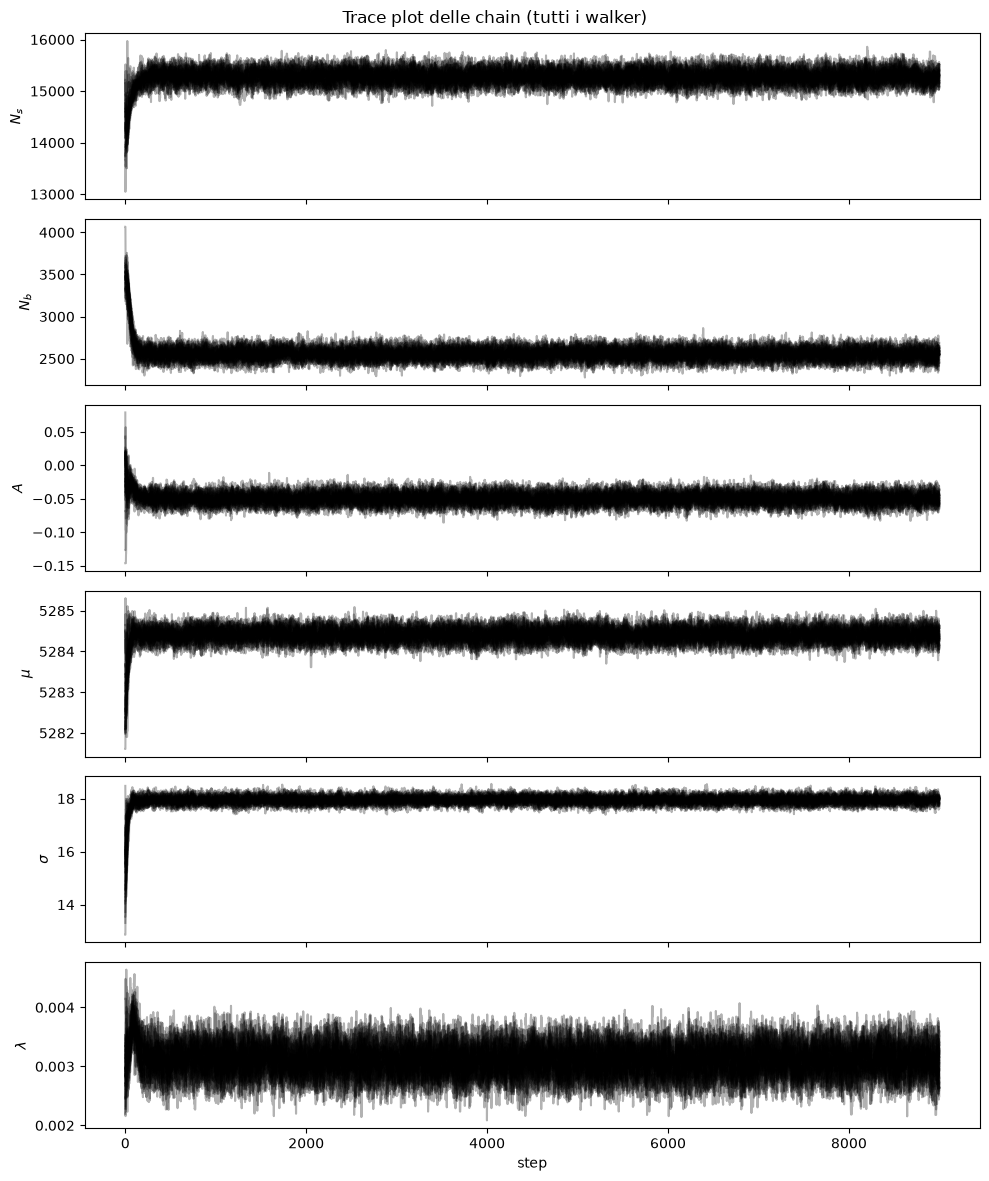

In [8]:
try:
    tau = sampler.get_autocorr_time()
    print("autocorrelation time per parametro:")
    for name, t in zip(bm.PARAM_NAMES, tau):
        print(f"  {name:12s} tau={t:.1f}  (n_eff ~= {nsteps*nwalkers/t:.0f})")
except emcee.autocorr.AutocorrError as e:
    print("Warning: catena forse troppo corta per una stima affidabile di tau:", e)

fig, axes = plt.subplots(ndim, figsize=(10, 12), sharex=True)
chain = sampler.get_chain()
for i in range(ndim):
    axes[i].plot(chain[:, :, i], alpha=0.3, color="k")
    axes[i].set_ylabel(bm.PARAM_LABELS[i])
axes[-1].set_xlabel("step")
fig.suptitle("Trace plot delle chain (tutti i walker)")
plt.tight_layout()
plt.show()

In [9]:
discard = nsteps // 6  # ~1/6 of the chain as burn-in
flat_samples = sampler.get_chain(discard=discard, flat=True)
print(f"discarded first {discard} steps as burn-in, {len(flat_samples)} samples remaining")

discarded first 1500 steps as burn-in, 240000 samples remaining


## Bayesian outputs

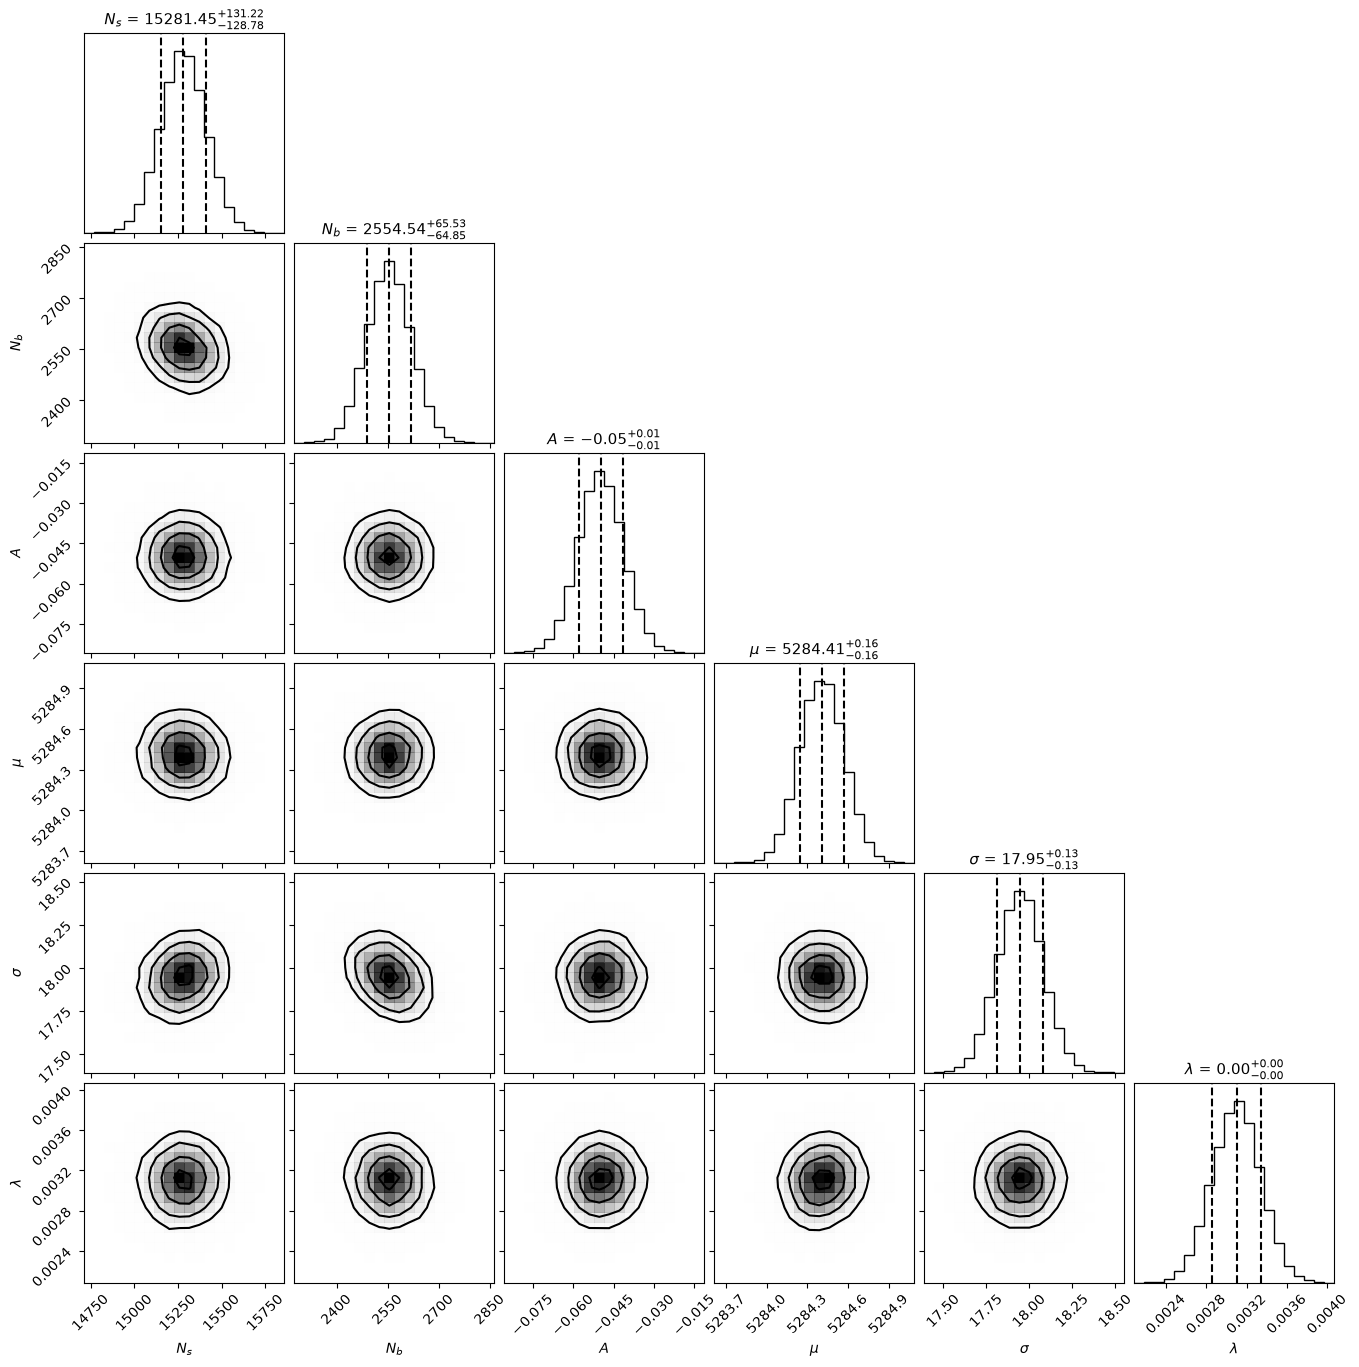

In [10]:
fig = corner.corner(
    flat_samples,
    labels=bm.PARAM_LABELS,
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    plot_datapoints=False,
    title_kwargs={"fontsize": 11},
)
plt.show()

In [11]:
A_samples = flat_samples[:, bm.PARAM_NAMES.index("A")]
A_median = np.median(A_samples)
ci68 = np.percentile(A_samples, [16, 84])
ci95 = np.percentile(A_samples, [2.5, 97.5])

print(f"A_raw (posterior median) = {A_median:.4f}")
print(f"  68% credible interval: [{ci68[0]:.4f}, {ci68[1]:.4f}]")
print(f"  95% credible interval: [{ci95[0]:.4f}, {ci95[1]:.4f}]")

checkpoint_save("main_posterior_checkpoint", {
    "A_raw_median": float(A_median), "A_raw_ci68": [float(ci68[0]), float(ci68[1])],
    "A_raw_ci95": [float(ci95[0]), float(ci95[1])], "n_events": int(len(m_obs)),
})

A_raw (posterior median) = -0.0497
  68% credible interval: [-0.0579, -0.0413]
  95% credible interval: [-0.0659, -0.0331]
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/main_posterior_checkpoint.json


### Posterior predictive check (qualitative)

Model curve with the parameters at their posterior medians, overlaid on the data histogram (separately for $B^+$ and $B^-$).

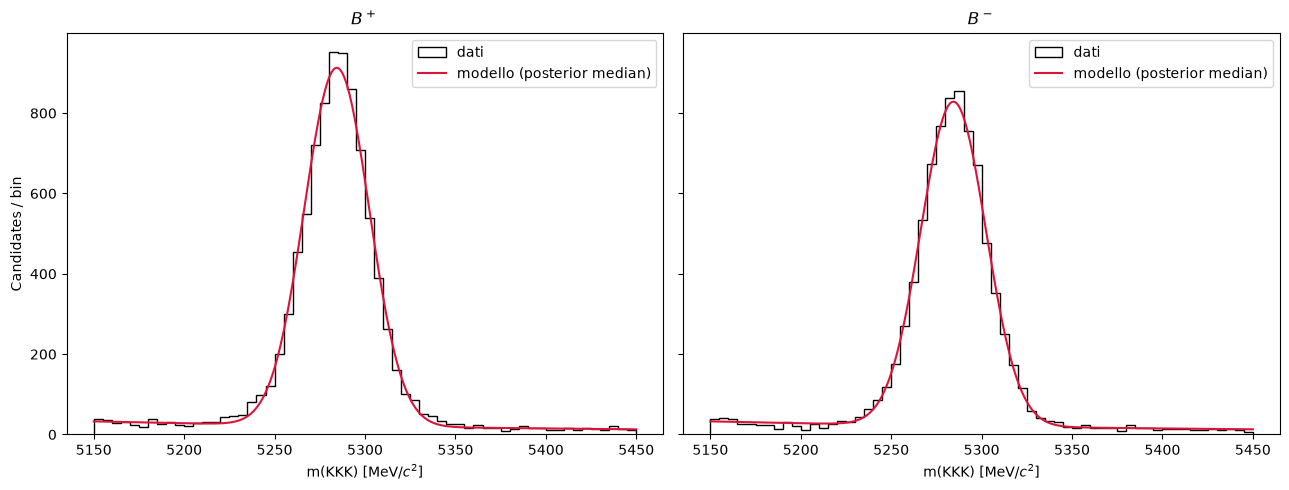

In [12]:
theta_med = np.median(flat_samples, axis=0)
N_s, N_b, A, mu, sigma, lam = theta_med
N_s_plus, N_s_minus, N_b_half = N_s*(1-A)/2, N_s*(1+A)/2, N_b/2

m_grid = np.linspace(bm.MASS_LO, bm.MASS_HI, 300)
bin_width = bins[1] - bins[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, q_sign, N_s_q, label in (
    (axes[0], 1, N_s_plus, r"$B^+$"),
    (axes[1], -1, N_s_minus, r"$B^-$"),
):
    ax.hist(m_obs[q_obs == q_sign], bins=bins, histtype="step", color="k", label="dati")
    model_curve = (N_s_q * bm.signal_pdf(m_grid, mu, sigma) + N_b_half * bm.background_pdf(m_grid, lam)) * bin_width
    ax.plot(m_grid, model_curve, color="crimson", label="modello (posterior median)")
    ax.set_xlabel("m(KKK) [MeV/$c^2$]")
    ax.set_title(label)
    ax.legend()
axes[0].set_ylabel("Candidates / bin")
plt.tight_layout()
plt.show()

## Bayes factor: A = 0 vs A free

Integrating the evidence on a grid does not scale to a six-parameter posterior. Since $A=0$ is nested in the free model and the other priors are shared, the Bayes factor is the **Savage-Dickey ratio**: $BF_{01} = p(A=0\mid\text{data}) / \pi(A=0)$. The posterior density at $A=0$ is first estimated with a KDE on the $A$ column of the chain; the prior density is $1/2$ (uniform on $[-1,1]$). Equal prior odds for $H_0$ ($A=0$) and $H_1$ ($A$ free), so the Bayes factor equals the posterior odds.

In [13]:
kde = gaussian_kde(A_samples)
posterior_density_at_0 = float(kde(0.0)[0])
prior_density_A = 1.0 / (bm.PRIOR_BOUNDS["A"][1] - bm.PRIOR_BOUNDS["A"][0])  # uniform prior density

BF_01 = posterior_density_at_0 / prior_density_A
print(f"posterior density of A at 0: {posterior_density_at_0:.3e}")
print(f"prior density of A at 0:     {prior_density_A:.4f}")
print(f"Savage-Dickey Bayes factor BF_01 (H0: A=0  vs  H1: A libero): {BF_01:.3e}")
print("(BF_01 > 1 favorisce H0/A=0; scala di Jeffreys: >3 evidenza moderata, >10 forte, >100 decisiva)")
n_sigma_away = abs(0.0 - A_median) / A_samples.std()
print()
print(f"A=0 e' a ~{n_sigma_away:.1f} deviazioni standard del posterior dal valore osservato:")
print("la KDE sta estrapolando molto in coda -> il valore esatto di BF_01 e' numericamente fragile,")
print("ma la conclusione qualitativa (evidenza estrema contro A=0) e' robusta.")

posterior density of A at 0: 1.607e-59
prior density of A at 0:     0.5000
Savage-Dickey Bayes factor BF_01 (H0: A=0  vs  H1: A libero): 3.214e-59
(BF_01 > 1 favorisce H0/A=0; scala di Jeffreys: >3 evidenza moderata, >10 forte, >100 decisiva)

A=0 e' a ~6.0 deviazioni standard del posterior dal valore osservato:
la KDE sta estrapolando molto in coda -> il valore esatto di BF_01 e' numericamente fragile,
ma la conclusione qualitativa (evidenza estrema contro A=0) e' robusta.


### Sensitivity of the Bayes factor to the KDE bandwidth

Explicit check of how reliable the number is: $BF_{01}$ is recomputed with the KDE bandwidth scaled with respect to Silverman's rule, without rerunning the MCMC.

bandwidth x0.5 (silverman factor=0.0420): BF_01 = 2.500e-228
bandwidth x1.0 (silverman factor=0.0839): BF_01 = 3.214e-59
bandwidth x1.5 (silverman factor=0.1259): BF_01 = 5.048e-28
bandwidth x2.0 (silverman factor=0.1679): BF_01 = 3.618e-17
bandwidth x3.0 (silverman factor=0.2518): BF_01 = 1.681e-09


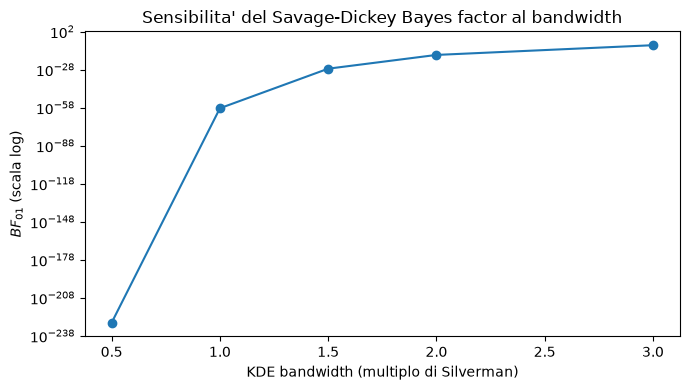


BF_01 varia di 6.7e+218 volte su questo range di bandwidth.
Conclusione: il VALORE ESATTO del Bayes factor non e' affidabile qui (A=0 e' troppo
in coda al posterior perche' Savage-Dickey via KDE funzioni bene). La conclusione
QUALITATIVA -- evidenza estrema/decisiva contro A=0 -- resta pero' robusta su tutto il range.


In [14]:
bw_multipliers = [0.5, 1.0, 1.5, 2.0, 3.0]
bf_vs_bw = []
for factor in bw_multipliers:
    kde_i = gaussian_kde(A_samples)
    kde_i.set_bandwidth(kde_i.factor * factor)
    dens0_i = float(kde_i(0.0)[0])
    bf_i = dens0_i / prior_density_A
    bf_vs_bw.append(bf_i)
    print(f"bandwidth x{factor:.1f} (silverman factor={kde_i.factor:.4f}): BF_01 = {bf_i:.3e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(bw_multipliers, bf_vs_bw, "o-")
ax.set_xlabel("KDE bandwidth (multiplo di Silverman)")
ax.set_ylabel(r"$BF_{01}$ (scala log)")
ax.set_title("Sensibilita' del Savage-Dickey Bayes factor al bandwidth")
plt.tight_layout()
plt.show()

print()
print(f"BF_01 varia di {max(bf_vs_bw)/min(bf_vs_bw):.1e} volte su questo range di bandwidth.")
print("Conclusione: il VALORE ESATTO del Bayes factor non e' affidabile qui (A=0 e' troppo")
print("in coda al posterior perche' Savage-Dickey via KDE funzioni bene). La conclusione")
print("QUALITATIVA -- evidenza estrema/decisiva contro A=0 -- resta pero' robusta su tutto il range.")

In [15]:
# A=0 is ~6 sd away: the KDE is not reliable so far in the tail. The marginal posterior of A is nearly Gaussian,
# so the density at 0 is estimated with the Gaussian approximation.
from scipy.stats import norm as _norm_bf
sd_A_post = float(np.std(A_samples))
BF_01_gauss = float(_norm_bf.pdf(0.0, np.mean(A_samples), sd_A_post) / prior_density_A)
print(f"approssimazione gaussiana: sd(A)={sd_A_post:.4f}, BF_01={BF_01_gauss:.2e}, ln BF_10={np.log(1/BF_01_gauss):.1f}")

approssimazione gaussiana: sd(A)=0.0084, BF_01=2.06e-06, ln BF_10=13.1


## Cross-check: magnet up vs magnet down

The two magnet polarities have opposite left-right detection asymmetries (summing them partially cancels them). The same model is fitted separately to the two polarities and $A_{raw}$ is compared: if they agree with each other and with the combined result, the asymmetry is not an instrumental artefact of one polarity. Shorter chain (5000 steps) than the main one: a comparison, not the final precision.

In [16]:
def fit_subset(m_sub, q_sub, label, nsteps_sub=5000, nwalkers_sub=32):
    theta0_sub = np.array([bm.INITIAL_GUESS[n] for n in bm.PARAM_NAMES])
    # scale the yield guesses to the subset size
    scale = len(m_sub) / len(m_obs)
    theta0_sub[0] *= scale  # N_s
    theta0_sub[1] *= scale  # N_b

    spread_sub = np.array([0.05*theta0_sub[0], 0.08*theta0_sub[1], 0.08, 1.5, 1.5, 0.2*theta0_sub[5]])
    pos_sub = theta0_sub + spread_sub * np.random.default_rng(7).standard_normal((nwalkers_sub, ndim))
    pos_sub[:, 2] = np.clip(pos_sub[:, 2], -0.5, 0.5)

    sampler_sub = emcee.EnsembleSampler(nwalkers_sub, ndim, bm.log_posterior, args=(m_sub, q_sub))
    sampler_sub.run_mcmc(pos_sub, nsteps_sub, progress=False)

    discard_sub = nsteps_sub // 6
    flat_sub = sampler_sub.get_chain(discard=discard_sub, flat=True)
    A_sub = flat_sub[:, bm.PARAM_NAMES.index("A")]
    med = float(np.median(A_sub))
    ci = [float(x) for x in np.percentile(A_sub, [16, 84])]
    acc = float(np.mean(sampler_sub.acceptance_fraction))
    print(f"{label}: n={len(m_sub)}  A_raw={med:.4f}  68% CI=[{ci[0]:.4f},{ci[1]:.4f}]  acceptance={acc:.2f}")
    return {"n": len(m_sub), "A_median": med, "A_ci68": ci, "acceptance": acc, "A_samples": A_sub}

mask_down = magnet_obs == "down"
mask_up = magnet_obs == "up"

result_down = fit_subset(m_obs[mask_down], q_obs[mask_down], "Magnet DOWN")
result_up = fit_subset(m_obs[mask_up], q_obs[mask_up], "Magnet UP")

diff = result_down["A_median"] - result_up["A_median"]
combined_unc = np.sqrt(np.diff(result_down["A_ci68"])[0]**2 + np.diff(result_up["A_ci68"])[0]**2) / 2
print(f"\ndifferenza A_raw(down) - A_raw(up) = {diff:.4f}  (~{abs(diff)/combined_unc:.1f} sigma combinate)")

checkpoint_save("magnet_updown_checkpoint", {
    "down": {"n": result_down["n"], "A_median": result_down["A_median"], "A_ci68": result_down["A_ci68"]},
    "up": {"n": result_up["n"], "A_median": result_up["A_median"], "A_ci68": result_up["A_ci68"]},
    "diff": float(diff),
})

Magnet DOWN: n=10500  A_raw=-0.0548  68% CI=[-0.0654,-0.0441]  acceptance=0.52


Magnet UP: n=7339  A_raw=-0.0426  68% CI=[-0.0558,-0.0298]  acceptance=0.52

differenza A_raw(down) - A_raw(up) = -0.0122  (~0.7 sigma combinate)
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/magnet_updown_checkpoint.json


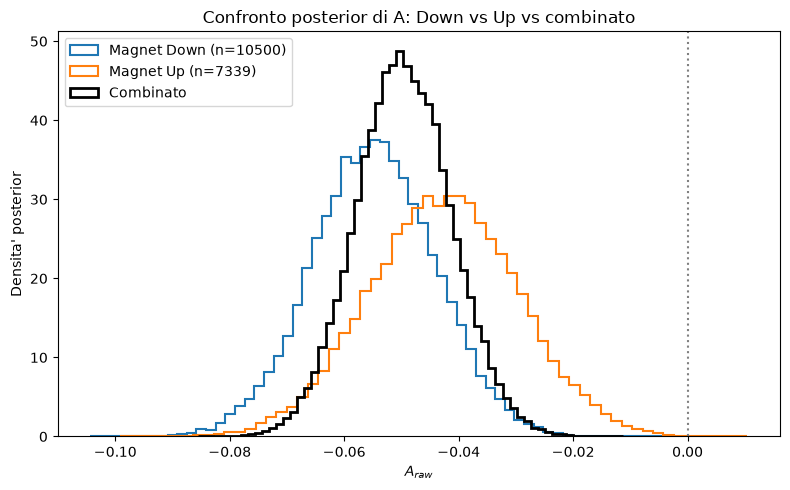

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(result_down["A_samples"], bins=60, density=True, histtype="step", label=f"Magnet Down (n={result_down['n']})", linewidth=1.5)
ax.hist(result_up["A_samples"], bins=60, density=True, histtype="step", label=f"Magnet Up (n={result_up['n']})", linewidth=1.5)
ax.hist(A_samples, bins=60, density=True, histtype="step", label="Combinato", color="k", linewidth=2)
ax.axvline(0, color="gray", linestyle=":")
ax.set_xlabel(r"$A_{raw}$")
ax.set_ylabel("Densita' posterior")
ax.legend()
ax.set_title("Confronto posterior di A: Down vs Up vs combinato")
plt.tight_layout()
plt.show()

## Cross-check: charge symmetry of the background

The model assumes $N_b^+=N_b^-=N_b/2$ (no background asymmetry). Direct check: in the sidebands ($|m-\mu|>4\sigma$, dominated by combinatorial background) the counting asymmetry should be compatible with zero if the background were charge symmetric.

In [18]:
mu_post = np.median(flat_samples[:, bm.PARAM_NAMES.index("mu")])
sigma_post = np.median(flat_samples[:, bm.PARAM_NAMES.index("sigma")])
side_gap_lo_bg, side_gap_hi_bg = mu_post - 4*sigma_post, mu_post + 4*sigma_post
is_sideband_bg = (m_obs < side_gap_lo_bg) | (m_obs > side_gap_hi_bg)

q_sb = q_obs[is_sideband_bg]
n_plus_sb, n_minus_sb = int(np.sum(q_sb == 1)), int(np.sum(q_sb == -1))
n_tot_sb = n_plus_sb + n_minus_sb
A_sb = (n_minus_sb - n_plus_sb) / n_tot_sb
sigma_A_sb = np.sqrt(max(1 - A_sb**2, 0) / n_tot_sb)
print(f"sidebands (|m-mu_post|>4sigma_post, fuori [{side_gap_lo_bg:.1f},{side_gap_hi_bg:.1f}] MeV): n={n_tot_sb}")
print(f"  n+ = {n_plus_sb}   n- = {n_minus_sb}")
print(f"  A_sideband = {A_sb:+.4f} +- {sigma_A_sb:.4f}  ({abs(A_sb)/sigma_A_sb:.2f} sigma da zero)")

lo_sb, hi_sb = m_obs < side_gap_lo_bg, m_obs > side_gap_hi_bg
for name, mask_sb in [("sideband bassa", lo_sb), ("sideband alta", hi_sb)]:
    qq = q_obs[mask_sb]
    npl, nmi = int(np.sum(qq == 1)), int(np.sum(qq == -1))
    ntot = npl + nmi
    A_ = (nmi - npl) / ntot if ntot > 0 else float("nan")
    sA_ = np.sqrt(max(1 - A_**2, 0) / ntot) if ntot > 0 else float("nan")
    print(f"  {name}: n={ntot} (n+={npl}, n-={nmi})  A={A_:+.4f} +- {sA_:.4f}")

checkpoint_save("sideband_symmetry_checkpoint", {
    "mu_post": float(mu_post), "sigma_post": float(sigma_post),
    "n_sideband": n_tot_sb, "n_plus": n_plus_sb, "n_minus": n_minus_sb,
    "A_sideband": float(A_sb), "sigma_A_sideband": float(sigma_A_sb),
})

sidebands (|m-mu_post|>4sigma_post, fuori [5212.6,5356.2] MeV): n=1217
  n+ = 637   n- = 580
  A_sideband = -0.0468 +- 0.0286  (1.64 sigma da zero)
  sideband bassa: n=689 (n+=359, n-=330)  A=-0.0421 +- 0.0381
  sideband alta: n=528 (n+=278, n-=250)  A=-0.0530 +- 0.0435
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/sideband_symmetry_checkpoint.json


### Fit with free background asymmetry

Instead of assuming $N_b^+=N_b^-$, the background asymmetry is free: $N_b^\pm = N_b(1\mp A_b)/2$, uniform prior $A_b\in(-1,1)$. Same sampler and chain length as the nominal fit.

In [19]:
plus_obs = q_obs > 0

def log_posterior_free_bkg(theta):
    N_s_, N_b_, A_, A_b_, mu_, sig_, lam_ = theta
    N = len(m_obs)
    if not (0 < N_s_ < 5*N and 0 < N_b_ < 5*N and -1 < A_ < 1 and -1 < A_b_ < 1
            and 5260 < mu_ < 5310 and 3 < sig_ < 40 and 1e-5 < lam_ < 0.05):
        return -np.inf
    s_ = bm.signal_pdf(m_obs, mu_, sig_); b_ = bm.background_pdf(m_obs, lam_)
    dp = N_s_*(1-A_)/2*s_[plus_obs] + N_b_*(1-A_b_)/2*b_[plus_obs]
    dm = N_s_*(1+A_)/2*s_[~plus_obs] + N_b_*(1+A_b_)/2*b_[~plus_obs]
    if np.any(dp <= 0) or np.any(dm <= 0):
        return -np.inf
    return np.sum(np.log(dp)) + np.sum(np.log(dm)) - (N_s_ + N_b_)

theta0_fb = np.array([15281., 2555., -0.05, 0.0, 5284.4, 17.95, 0.0031])
spread_fb = np.array([0.03*theta0_fb[0], 0.05*theta0_fb[1], 0.05, 0.05, 1.0, 1.0, 0.15*theta0_fb[6]])
pos_fb = theta0_fb + spread_fb * np.random.default_rng(42).standard_normal((32, 7))
sampler_fb = emcee.EnsembleSampler(32, 7, log_posterior_free_bkg)
sampler_fb.run_mcmc(pos_fb, 9000, progress=False)
flat_fb = sampler_fb.get_chain(discard=1500, flat=True)
tau_fb = sampler_fb.get_autocorr_time(discard=1500, quiet=True)

A_fb, Ab_fb = flat_fb[:, 2], flat_fb[:, 3]
from scipy.stats import norm as _norm_fb
BF_10_Ab = float(0.5 / _norm_fb.pdf(0.0, np.mean(Ab_fb), np.std(Ab_fb)))  # Savage-Dickey, Gaussian approximation
free_bkg_summary = {
    "A_median": float(np.median(A_fb)), "A_ci68": [float(x) for x in np.percentile(A_fb, [16, 84])],
    "A_b_median": float(np.median(Ab_fb)), "A_b_sd": float(np.std(Ab_fb)),
    "A_b_ci68": [float(x) for x in np.percentile(Ab_fb, [16, 84])],
    "corr_A_Ab": float(np.corrcoef(A_fb, Ab_fb)[0, 1]), "BF_10_Ab": BF_10_Ab,
    "acceptance": float(np.mean(sampler_fb.acceptance_fraction)), "tau_max": float(np.max(tau_fb)),
}
print(f"fondo libero: A = {free_bkg_summary['A_median']:.4f}  68% CI={free_bkg_summary['A_ci68']}")
print(f"              A_b = {free_bkg_summary['A_b_median']:.3f} +- {free_bkg_summary['A_b_sd']:.3f} "
      f"({abs(free_bkg_summary['A_b_median'])/free_bkg_summary['A_b_sd']:.1f} sigma da zero), BF_10={BF_10_Ab:.1f}")
print(f"              spostamento di A rispetto al nominale: {free_bkg_summary['A_median'] - A_median:+.4f}")
checkpoint_save("free_background_checkpoint", free_bkg_summary)

fondo libero: A = -0.0457  68% CI=[-0.05395908874332569, -0.03706700711715227]
              A_b = -0.071 +- 0.024 (2.9 sigma da zero), BF_10=2.2
              spostamento di A rispetto al nominale: +0.0040
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/free_background_checkpoint.json


### Chains from dispersed starting points

Several independent chains from different starting points: the nominal fit is repeated twice with the 32 walkers spread uniformly over the whole prior box.

In [20]:
lo_box = np.array([bm.PRIOR_BOUNDS[n][0] for n in bm.PARAM_NAMES])
hi_box = np.array([bm.PRIOR_BOUNDS[n][1] for n in bm.PARAM_NAMES])
dispersed_summary = []
for seed_d in (1, 2):
    pos_d = lo_box + (hi_box - lo_box) * np.random.default_rng(seed_d).uniform(0.02, 0.98, (nwalkers, ndim))
    sampler_d = emcee.EnsembleSampler(nwalkers, ndim, bm.log_posterior, args=(m_obs, q_obs))
    sampler_d.run_mcmc(pos_d, nsteps, progress=False)
    chain_d = sampler_d.get_chain()
    in_bulk = (np.abs(chain_d[:, :, 2] - A_median) < 5 * np.std(A_samples)).all(axis=1)
    steps_to_bulk = int(np.argmax(in_bulk)) if in_bulk.any() else -1
    A_d = sampler_d.get_chain(discard=discard, flat=True)[:, 2]
    r_d = {"seed": seed_d, "steps_to_bulk": steps_to_bulk, "A_median": float(np.median(A_d)),
           "A_ci68": [float(x) for x in np.percentile(A_d, [16, 84])]}
    dispersed_summary.append(r_d)
    print(f"seed {seed_d}: walker nel bulk dopo {steps_to_bulk} step; A = {r_d['A_median']:.4f}  68% CI={r_d['A_ci68']}")
print(f"nominale: A = {A_median:.4f}  68% CI=[{ci68[0]:.4f},{ci68[1]:.4f}]")
checkpoint_save("dispersed_start_checkpoint", {"runs": dispersed_summary})

seed 1: walker nel bulk dopo 138 step; A = -0.0495  68% CI=[-0.05780506422324604, -0.04105073758985638]


seed 2: walker nel bulk dopo 133 step; A = -0.0496  68% CI=[-0.05804555700321742, -0.04123486363407702]
nominale: A = -0.0497  68% CI=[-0.0579,-0.0413]
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/dispersed_start_checkpoint.json


### Charm vetoes

$B^\pm\to D^0K^\pm$, $J/\psi K^\pm$, $\chi_{c0}K^\pm$ with $D^0, J/\psi, \chi_{c0}\to K^+K^-$ are not charmless. Candidates with at least one opposite-sign pair within $\pm30$ MeV of the resonance mass are excluded and the nominal fit is repeated.

In [21]:
ch_v = data[["H1_Charge", "H2_Charge", "H3_Charge"]].to_numpy()
bach_v = np.argmax(ch_v != np.sign(data["B_Charge"].to_numpy())[:, None], axis=1)
same_v = np.array([[j for j in range(3) if j != b] for b in bach_v])
E_v = data[["H1_E", "H2_E", "H3_E"]].to_numpy(); PX_v = data[["H1_PX", "H2_PX", "H3_PX"]].to_numpy()
PY_v = data[["H1_PY", "H2_PY", "H3_PY"]].to_numpy(); PZ_v = data[["H1_PZ", "H2_PZ", "H3_PZ"]].to_numpy()
r_v = np.arange(len(data))

def m_pair_v(i, j):
    return np.sqrt(np.clip((E_v[r_v, i] + E_v[r_v, j])**2 - (PX_v[r_v, i] + PX_v[r_v, j])**2
                           - (PY_v[r_v, i] + PY_v[r_v, j])**2 - (PZ_v[r_v, i] + PZ_v[r_v, j])**2, 0, None))

m_a_v, m_b_v = m_pair_v(bach_v, same_v[:, 0]), m_pair_v(bach_v, same_v[:, 1])

charm_veto_summary = {}
for label_v, states_v in (("D0", [1864.84]), ("D0_Jpsi_chic0", [1864.84, 3096.9, 3414.7])):
    veto_v = np.zeros(len(data), bool)
    for m0 in states_v:
        veto_v |= (np.abs(m_a_v - m0) < 30) | (np.abs(m_b_v - m0) < 30)
    m_k, q_k = m_obs[~veto_v], q_obs[~veto_v]
    th0_v = theta0.copy(); th0_v[:2] *= len(m_k) / len(m_obs)
    sp_v = np.array([0.03*th0_v[0], 0.05*th0_v[1], 0.05, 1.0, 1.0, 0.15*th0_v[5]])
    pos_v = th0_v + sp_v * np.random.default_rng(42).standard_normal((nwalkers, ndim))
    pos_v[:, 2] = np.clip(pos_v[:, 2], -0.5, 0.5)
    sampler_vt = emcee.EnsembleSampler(nwalkers, ndim, bm.log_posterior, args=(m_k, q_k))
    sampler_vt.run_mcmc(pos_v, nsteps, progress=False)
    A_vt = sampler_vt.get_chain(discard=discard, flat=True)[:, 2]
    q_rm = q_obs[veto_v]
    charm_veto_summary[label_v] = {
        "n_kept": int(len(m_k)), "n_removed": int(veto_v.sum()),
        "A_count_removed": float((np.sum(q_rm < 0) - np.sum(q_rm > 0)) / max(len(q_rm), 1)),
        "A_median": float(np.median(A_vt)), "A_ci68": [float(x) for x in np.percentile(A_vt, [16, 84])]}
    print(f"veto {label_v}: rimossi {veto_v.sum()}, A = {charm_veto_summary[label_v]['A_median']:.4f}  "
          f"68% CI={charm_veto_summary[label_v]['A_ci68']}  "
          f"(spostamento {charm_veto_summary[label_v]['A_median'] - A_median:+.4f})")
checkpoint_save("charm_veto_checkpoint", charm_veto_summary)

veto D0: rimossi 830, A = -0.0549  68% CI=[-0.06347423007486352, -0.04622619627822806]  (spostamento -0.0051)


veto D0_Jpsi_chic0: rimossi 2393, A = -0.0509  68% CI=[-0.05970411699447013, -0.04179262299234238]  (spostamento -0.0011)
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/charm_veto_checkpoint.json


## Toy-MC coverage check

Pseudo-datasets sampled from the *fitted* model (parametric bootstrap, same size as the data), with the observed value as $A_{\rm true}$, refitted with a shorter chain; the fraction of replicas whose 68% credible interval contains $A_{\rm true}$ is the empirical coverage. If it is close to the nominal 68%, the credible intervals above are reliable; if much lower, they are too narrow.

In [22]:
def sample_truncated_exponential(rng, lam, lo, hi, n):
    u = rng.uniform(0, 1, n)
    W = hi - lo
    return lo - np.log(1 - u * (1 - np.exp(-lam * W))) / lam

def sample_truncated_normal(rng, mu, sigma, lo, hi, n):
    from scipy.stats import truncnorm
    a, b = (lo - mu) / sigma, (hi - mu) / sigma
    return truncnorm.rvs(a, b, loc=mu, scale=sigma, size=n, random_state=rng)

def generate_toy(rng, theta_true):
    N_s, N_b, A, mu, sigma, lam = theta_true
    N_s_plus = rng.poisson(N_s * (1 - A) / 2)
    N_s_minus = rng.poisson(N_s * (1 + A) / 2)
    N_b_plus = rng.poisson(N_b / 2)
    N_b_minus = rng.poisson(N_b / 2)

    m_sp = sample_truncated_normal(rng, mu, sigma, bm.MASS_LO, bm.MASS_HI, N_s_plus)
    m_sm = sample_truncated_normal(rng, mu, sigma, bm.MASS_LO, bm.MASS_HI, N_s_minus)
    m_bp = sample_truncated_exponential(rng, lam, bm.MASS_LO, bm.MASS_HI, N_b_plus)
    m_bm = sample_truncated_exponential(rng, lam, bm.MASS_LO, bm.MASS_HI, N_b_minus)

    m_toy = np.concatenate([m_sp, m_sm, m_bp, m_bm])
    q_toy = np.concatenate([np.full(N_s_plus, 1), np.full(N_s_minus, -1),
                             np.full(N_b_plus, 1), np.full(N_b_minus, -1)])
    return m_toy, q_toy

theta_true = theta_med.copy()  # inject the observed posterior median as ground truth
print("theta_true used for toy generation:", dict(zip(bm.PARAM_NAMES, theta_true)))

theta_true used for toy generation: {'N_s': np.float64(15281.451208062927), 'N_b': np.float64(2554.541047168116), 'A': np.float64(-0.04972502482826961), 'mu': np.float64(5284.409866809464), 'sigma': np.float64(17.948108073420144), 'lambda_bkg': np.float64(0.0031029873771233852)}


In [23]:
N_TOYS = 500
NSTEPS_TOY = 3500
NWALKERS_TOY = 32

rng = np.random.default_rng(123)
covered_68 = 0
covered_95 = 0
toy_A_medians = []

for i in range(N_TOYS):
    m_toy, q_toy = generate_toy(rng, theta_true)

    spread_toy = np.array([0.05*theta_true[0], 0.08*theta_true[1], 0.08, 1.5, 1.5, 0.2*theta_true[5]])
    pos_toy = theta_true + spread_toy * rng.standard_normal((NWALKERS_TOY, ndim))
    pos_toy[:, 2] = np.clip(pos_toy[:, 2], -0.9, 0.9)

    sampler_toy = emcee.EnsembleSampler(NWALKERS_TOY, ndim, bm.log_posterior, args=(m_toy, q_toy))
    sampler_toy.run_mcmc(pos_toy, NSTEPS_TOY, progress=False)

    flat_toy = sampler_toy.get_chain(discard=NSTEPS_TOY // 6, flat=True)
    A_toy = flat_toy[:, bm.PARAM_NAMES.index("A")]
    ci68_toy = np.percentile(A_toy, [16, 84])
    ci95_toy = np.percentile(A_toy, [2.5, 97.5])
    toy_A_medians.append(np.median(A_toy))

    in68 = ci68_toy[0] <= theta_true[2] <= ci68_toy[1]
    in95 = ci95_toy[0] <= theta_true[2] <= ci95_toy[1]
    covered_68 += in68
    covered_95 += in95
    print(f"toy {i+1:2d}/{N_TOYS}: A_hat={np.median(A_toy):+.4f}  68% CI=[{ci68_toy[0]:+.4f},{ci68_toy[1]:+.4f}]  "
          f"in68={in68}  in95={in95}")
    if (i + 1) % 5 == 0 or (i + 1) == N_TOYS:
        checkpoint_save("toy_mc_coverage_progress", {
            "n_done": i + 1, "n_total": N_TOYS,
            "coverage_68_so_far": covered_68 / (i + 1), "coverage_95_so_far": covered_95 / (i + 1),
            "toy_A_medians_so_far": toy_A_medians,
        })

cov68_frac = covered_68 / N_TOYS
cov95_frac = covered_95 / N_TOYS
print(f"\nempirical 68% coverage: {covered_68}/{N_TOYS} = {cov68_frac:.2f} (nominale: 0.68)")
print(f"empirical 95% coverage: {covered_95}/{N_TOYS} = {cov95_frac:.2f} (nominale: 0.95)")
checkpoint_save("toy_mc_coverage_final", {
    "n_toys": N_TOYS, "coverage_68": cov68_frac, "coverage_95": cov95_frac,
    "toy_A_medians": toy_A_medians,
})

toy  1/500: A_hat=-0.0554  68% CI=[-0.0632,-0.0471]  in68=True  in95=True


toy  2/500: A_hat=-0.0731  68% CI=[-0.0811,-0.0645]  in68=False  in95=False


toy  3/500: A_hat=-0.0443  68% CI=[-0.0524,-0.0361]  in68=True  in95=True


toy  4/500: A_hat=-0.0476  68% CI=[-0.0558,-0.0392]  in68=True  in95=True


toy  5/500: A_hat=-0.0421  68% CI=[-0.0505,-0.0339]  in68=True  in95=True
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/toy_mc_coverage_progress.json


...

toy 496/500: A_hat=-0.0431  68% CI=[-0.0513,-0.0349]  in68=True  in95=True


toy 497/500: A_hat=-0.0496  68% CI=[-0.0578,-0.0411]  in68=True  in95=True


toy 498/500: A_hat=-0.0494  68% CI=[-0.0578,-0.0411]  in68=True  in95=True


toy 499/500: A_hat=-0.0485  68% CI=[-0.0569,-0.0402]  in68=True  in95=True


toy 500/500: A_hat=-0.0466  68% CI=[-0.0547,-0.0385]  in68=True  in95=True
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/toy_mc_coverage_progress.json

empirical 68% coverage: 332/500 = 0.66 (nominale: 0.68)
empirical 95% coverage: 481/500 = 0.96 (nominale: 0.95)
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/toy_mc_coverage_final.json


In [24]:
# bias and spread of the toy estimates, compared with the posterior sd of the data fit
toy_arr = np.array(toy_A_medians)
toy_bias = float(toy_arr.mean() - theta_true[bm.PARAM_NAMES.index("A")])
toy_bias_err = float(toy_arr.std(ddof=1) / np.sqrt(len(toy_arr)))
toy_sd = float(toy_arr.std(ddof=1))
print(f"bias = {toy_bias:+.5f} +- {toy_bias_err:.5f}; sd delle stime = {toy_sd:.5f} vs sd posterior dati = {np.std(A_samples):.5f}")

bias = -0.00046 +- 0.00036; sd delle stime = 0.00799 vs sd posterior dati = 0.00835


## Systematic study

How much $A_{raw}$ changes under alternative modelling choices. Same chain length as the nominal fit (9000 steps, 32 walkers). Local pdfs, explicitly parametrized on a window $[lo,hi]$, so as not to touch the global constants of `bayesian_model.py`.

In [25]:
from scipy.stats import norm as _norm_syst

def signal_pdf_w(m, mu, sigma, lo, hi):
    norm_const = _norm_syst.cdf(hi, mu, sigma) - _norm_syst.cdf(lo, mu, sigma)
    return _norm_syst.pdf(m, mu, sigma) / norm_const

def background_pdf_exp_w(m, lam, lo, hi):
    num = lam * np.exp(-lam * (m - lo))
    den = 1.0 - np.exp(-lam * (hi - lo))
    return num / den

def background_pdf_lin_w(m, c, lo, hi):
    # c in (-1, 1): linear shape, guaranteed positive on [lo, hi]
    x = 2 * (m - lo) / (hi - lo) - 1  # maps [lo,hi] -> [-1,1]
    return (1 + c * x) / (hi - lo)

def log_posterior_syst(theta, m, q, lo, hi, bkg="exp", A_bound=1.0):
    N_s, N_b, A, mu, sigma, bkg_par = theta
    if not (0 < N_s < 5*len(m)): return -np.inf
    if not (0 < N_b < 5*len(m)): return -np.inf
    if not (-A_bound < A < A_bound): return -np.inf
    if not (lo+5 < mu < hi-5): return -np.inf
    if not (3 < sigma < 40): return -np.inf
    if bkg == "exp":
        if not (1e-5 < bkg_par < 0.05): return -np.inf
        b = background_pdf_exp_w(m, bkg_par, lo, hi)
    else:
        if not (-0.99 < bkg_par < 0.99): return -np.inf
        b = background_pdf_lin_w(m, bkg_par, lo, hi)

    s = signal_pdf_w(m, mu, sigma, lo, hi)
    N_s_plus, N_s_minus, N_b_half = N_s*(1-A)/2, N_s*(1+A)/2, N_b/2
    is_plus = q > 0
    dens_plus = N_s_plus*s[is_plus] + N_b_half*b[is_plus]
    dens_minus = N_s_minus*s[~is_plus] + N_b_half*b[~is_plus]
    if np.any(dens_plus <= 0) or np.any(dens_minus <= 0):
        return -np.inf
    ll = np.sum(np.log(dens_plus)) + np.sum(np.log(dens_minus)) - (N_s + N_b)
    return ll

def fit_variation(label, lo, hi, bkg="exp", A_bound=1.0, nsteps_v=9000, nwalkers_v=32):
    win_mask = (data.B_M > lo) & (data.B_M < hi)
    m_v = data.B_M.to_numpy()[win_mask]
    q_v = data.B_Charge.to_numpy()[win_mask]

    bkg_guess = bm.INITIAL_GUESS["lambda_bkg"] if bkg == "exp" else 0.0
    theta0_v = np.array([bm.INITIAL_GUESS["N_s"]*len(m_v)/len(m_obs), bm.INITIAL_GUESS["N_b"]*len(m_v)/len(m_obs),
                          0.0, bm.INITIAL_GUESS["mu"], bm.INITIAL_GUESS["sigma"], bkg_guess])
    spread_v = np.array([0.05*theta0_v[0], 0.08*theta0_v[1], 0.05, 1.5, 1.5,
                          0.2*bm.INITIAL_GUESS["lambda_bkg"] if bkg=="exp" else 0.1])
    pos_v = theta0_v + spread_v * np.random.default_rng(11).standard_normal((nwalkers_v, len(theta0_v)))
    pos_v[:, 2] = np.clip(pos_v[:, 2], -min(0.5, A_bound*0.9), min(0.5, A_bound*0.9))

    sampler_v = emcee.EnsembleSampler(nwalkers_v, len(theta0_v), log_posterior_syst,
                                        args=(m_v, q_v, lo, hi, bkg, A_bound))
    sampler_v.run_mcmc(pos_v, nsteps_v, progress=False)
    flat_v = sampler_v.get_chain(discard=nsteps_v//6, flat=True)
    A_v = flat_v[:, 2]
    med_v = float(np.median(A_v))
    ci_v = [float(x) for x in np.percentile(A_v, [16, 84])]
    print(f"{label:32s} n={len(m_v):6d}  A_raw={med_v:+.4f}  68% CI=[{ci_v[0]:+.4f},{ci_v[1]:+.4f}]")
    return {"label": label, "n": len(m_v), "A_median": med_v, "A_ci68": ci_v}

syst_results = [{"label": "Nominale (5150-5450, exp bkg)", "n": len(m_obs), "A_median": A_median, "A_ci68": [float(ci68[0]), float(ci68[1])]}]
syst_results.append(fit_variation("Finestra stretta (5200-5450)", 5200.0, 5450.0))
syst_results.append(fit_variation("Finestra corta in alto (5150-5400)", 5150.0, 5400.0))
syst_results.append(fit_variation("Fondo lineare (5150-5450)", 5150.0, 5450.0, bkg="lin"))
syst_results.append(fit_variation("Prior A stretto [-0.3,0.3] (5150-5450)", 5150.0, 5450.0, A_bound=0.3))

checkpoint_save("systematic_study_checkpoint", syst_results)

Finestra stretta (5200-5450)     n= 17267  A_raw=-0.0497  68% CI=[-0.0580,-0.0413]


Finestra corta in alto (5150-5400) n= 17590  A_raw=-0.0498  68% CI=[-0.0581,-0.0415]


Fondo lineare (5150-5450)        n= 17839  A_raw=-0.0498  68% CI=[-0.0581,-0.0415]


Prior A stretto [-0.3,0.3] (5150-5450) n= 17839  A_raw=-0.0495  68% CI=[-0.0577,-0.0414]
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/systematic_study_checkpoint.json


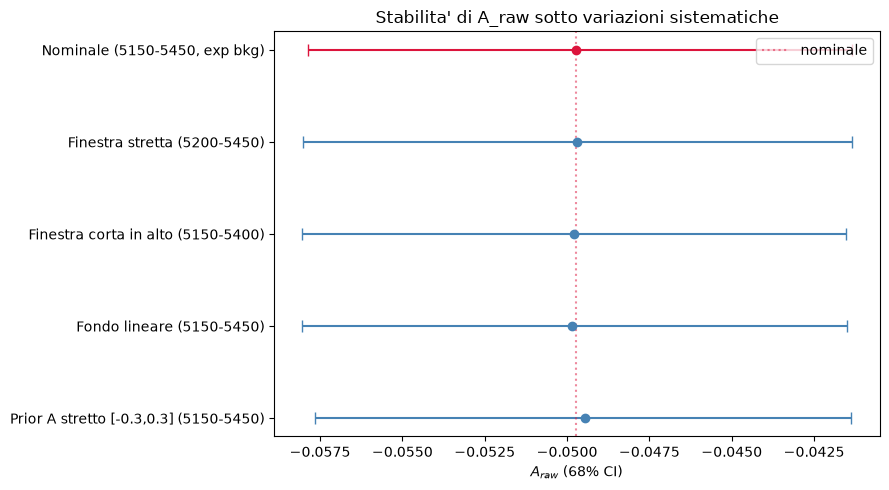

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))
ys = list(range(len(syst_results)))[::-1]
for y, r in zip(ys, syst_results):
    med, (lo_ci, hi_ci) = r["A_median"], r["A_ci68"]
    ax.errorbar(med, y, xerr=[[med-lo_ci], [hi_ci-med]], fmt="o", capsize=4,
                color="crimson" if "Nominale" in r["label"] else "steelblue")
ax.set_yticks(ys)
ax.set_yticklabels([r["label"] for r in syst_results])
ax.axvline(A_median, color="crimson", linestyle=":", alpha=0.5, label="nominale")
ax.set_xlabel(r"$A_{raw}$ (68% CI)")
ax.set_title("Stabilita' di A_raw sotto variazioni sistematiche")
ax.legend()
plt.tight_layout()
plt.show()

## Goodness of fit of the nominal (minimal) model

Binned pulls $(\text{observed} - \text{expected})/\sqrt{\text{expected}}$, separately for $B^+$ and $B^-$, with $\chi^2$/ndof as a numerical summary of the posterior predictive check above.

B+ : chi2 = 80.4 over 30 bins
B- : chi2 = 47.1 over 30 bins
Totale: chi2/ndof = 127.4 / 54 = 2.36
(vicino a 1 = buon accordo; se molto maggiore di 1 il modello minimale non basta)


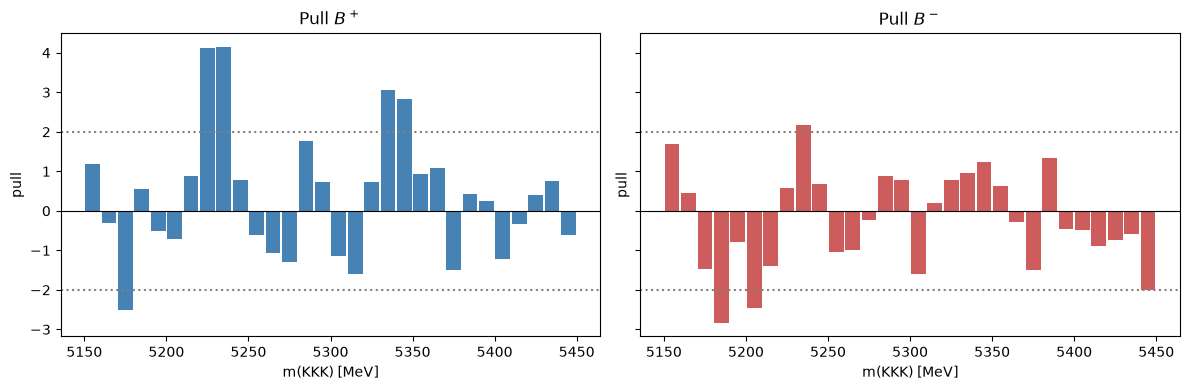

In [27]:
def binned_gof(m_data, bin_edges, N_s_q, N_b_half, mu, sigma, lam):
    bw = bin_edges[1] - bin_edges[0]
    obs, _ = np.histogram(m_data, bins=bin_edges)
    centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    exp = (N_s_q * bm.signal_pdf(centers, mu, sigma) + N_b_half * bm.background_pdf(centers, lam)) * bw
    pull = (obs - exp) / np.sqrt(np.maximum(exp, 1e-9))
    chi2 = np.sum(pull**2)
    return obs, exp, pull, chi2

gof_bins = np.linspace(bm.MASS_LO, bm.MASS_HI, 31)  # coarser binning for stable expected counts
obs_p, exp_p, pull_p, chi2_p = binned_gof(m_obs[q_obs > 0], gof_bins, N_s_plus, N_b_half, mu, sigma, lam)
obs_m, exp_m, pull_m, chi2_m = binned_gof(m_obs[q_obs < 0], gof_bins, N_s_minus, N_b_half, mu, sigma, lam)

ndof = 2 * (len(gof_bins) - 1) - ndim  # both charge samples, minus fitted parameters
chi2_tot = chi2_p + chi2_m
print(f"B+ : chi2 = {chi2_p:.1f} over {len(gof_bins)-1} bins")
print(f"B- : chi2 = {chi2_m:.1f} over {len(gof_bins)-1} bins")
print(f"Totale: chi2/ndof = {chi2_tot:.1f} / {ndof} = {chi2_tot/ndof:.2f}")
print("(vicino a 1 = buon accordo; se molto maggiore di 1 il modello minimale non basta)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
centers = 0.5 * (gof_bins[:-1] + gof_bins[1:])
axes[0].bar(centers, pull_p, width=(gof_bins[1]-gof_bins[0])*0.9, color="steelblue")
axes[0].set_title(r"Pull $B^+$"); axes[0].axhline(0, color="k", lw=0.8)
axes[1].bar(centers, pull_m, width=(gof_bins[1]-gof_bins[0])*0.9, color="indianred")
axes[1].set_title(r"Pull $B^-$"); axes[1].axhline(0, color="k", lw=0.8)
for ax in axes:
    ax.set_xlabel("m(KKK) [MeV]"); ax.set_ylabel("pull")
    ax.axhline(2, color="gray", ls=":"); ax.axhline(-2, color="gray", ls=":")
plt.tight_layout()
plt.show()

## Alternative signal model: Crystal Ball

The $\chi^2$/ndof above is not close to 1: the pure Gaussian is too simple. A **Crystal Ball** (Gaussian core with a power-law tail on the low-mass side, typical of radiative losses in B physics) is tried, first with the tail parameters ($\beta$, $m$) fixed to typical literature values ($\beta=1.5$, $m=3$), to keep the six-parameter setup.

In [28]:
from scipy.stats import crystalball as _cb

CB_BETA, CB_M = 1.5, 3.0  # fixed, not fitted

def signal_pdf_cb(m, mu, sigma, lo, hi):
    norm_const = _cb.cdf((hi - mu) / sigma, CB_BETA, CB_M) - _cb.cdf((lo - mu) / sigma, CB_BETA, CB_M)
    return _cb.pdf((m - mu) / sigma, CB_BETA, CB_M) / sigma / norm_const

def log_posterior_cb(theta, m, q, lo, hi):
    N_s, N_b, A, mu, sigma, lam = theta
    if not (0 < N_s < 5*len(m)): return -np.inf
    if not (0 < N_b < 5*len(m)): return -np.inf
    if not (-1 < A < 1): return -np.inf
    if not (lo+5 < mu < hi-5): return -np.inf
    if not (3 < sigma < 40): return -np.inf
    if not (1e-5 < lam < 0.05): return -np.inf

    s = signal_pdf_cb(m, mu, sigma, lo, hi)
    b = background_pdf_exp_w(m, lam, lo, hi)
    N_s_plus_, N_s_minus_, N_b_half_ = N_s*(1-A)/2, N_s*(1+A)/2, N_b/2
    is_plus_ = q > 0
    dp = N_s_plus_*s[is_plus_] + N_b_half_*b[is_plus_]
    dm = N_s_minus_*s[~is_plus_] + N_b_half_*b[~is_plus_]
    if np.any(dp <= 0) or np.any(dm <= 0):
        return -np.inf
    return np.sum(np.log(dp)) + np.sum(np.log(dm)) - (N_s + N_b)

theta0_cb = theta0.copy()
spread_cb = np.array([0.03*theta0_cb[0], 0.05*theta0_cb[1], 0.05, 1.0, 1.0, 0.15*theta0_cb[5]])
pos_cb = theta0_cb + spread_cb * np.random.default_rng(99).standard_normal((nwalkers, ndim))
pos_cb[:, 2] = np.clip(pos_cb[:, 2], -0.5, 0.5)

sampler_cb = emcee.EnsembleSampler(nwalkers, ndim, log_posterior_cb, args=(m_obs, q_obs, bm.MASS_LO, bm.MASS_HI))
sampler_cb.run_mcmc(pos_cb, 6000, progress=True)

flat_cb = sampler_cb.get_chain(discard=1000, flat=True)
A_cb = flat_cb[:, 2]
A_median_cb = float(np.median(A_cb))
ci68_cb = [float(x) for x in np.percentile(A_cb, [16, 84])]
print(f"\nCrystal Ball:  A_raw = {A_median_cb:.4f}  68% CI=[{ci68_cb[0]:.4f},{ci68_cb[1]:.4f}]  "
      f"acceptance={np.mean(sampler_cb.acceptance_fraction):.2f}")

theta_med_cb = np.median(flat_cb, axis=0)
N_s_cb, N_b_cb, A_cb_med, mu_cb, sigma_cb, lam_cb = theta_med_cb
N_s_plus_cb, N_s_minus_cb, N_b_half_cb = N_s_cb*(1-A_cb_med)/2, N_s_cb*(1+A_cb_med)/2, N_b_cb/2

def binned_gof_cb(m_data, bin_edges, N_s_q, N_b_half_, mu_, sigma_, lam_):
    bw = bin_edges[1] - bin_edges[0]
    obs, _ = np.histogram(m_data, bins=bin_edges)
    centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    exp = (N_s_q * signal_pdf_cb(centers, mu_, sigma_, bm.MASS_LO, bm.MASS_HI)
           + N_b_half_ * background_pdf_exp_w(centers, lam_, bm.MASS_LO, bm.MASS_HI)) * bw
    return np.sum((obs - exp)**2 / np.maximum(exp, 1e-9))

chi2_cb = (binned_gof_cb(m_obs[q_obs > 0], gof_bins, N_s_plus_cb, N_b_half_cb, mu_cb, sigma_cb, lam_cb)
           + binned_gof_cb(m_obs[q_obs < 0], gof_bins, N_s_minus_cb, N_b_half_cb, mu_cb, sigma_cb, lam_cb))
print(f"Crystal Ball chi2/ndof = {chi2_cb:.1f} / {ndof} = {chi2_cb/ndof:.2f}  "
      f"(gaussiana pura era {chi2_tot/ndof:.2f})")

checkpoint_save("crystal_ball_fixed_checkpoint", {
    "A_raw_median": A_median_cb, "A_raw_ci68": ci68_cb, "chi2_over_ndof": float(chi2_cb/ndof),
})

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 1/6000 [00:00<20:39,  4.84it/s]

  0%|          | 2/6000 [00:00<19:02,  5.25it/s]

  0%|          | 3/6000 [00:00<20:29,  4.88it/s]

  0%|          | 4/6000 [00:00<20:29,  4.88it/s]

...

100%|█████████▉| 5998/6000 [17:12<00:00,  6.24it/s]

100%|█████████▉| 5999/6000 [17:12<00:00,  6.44it/s]

100%|██████████| 6000/6000 [17:12<00:00,  6.28it/s]

100%|██████████| 6000/6000 [17:12<00:00,  5.81it/s]


Crystal Ball:  A_raw = -0.0512  68% CI=[-0.0595,-0.0431]  acceptance=0.52
Crystal Ball chi2/ndof = 242.9 / 54 = 4.50  (gaussiana pura era 2.36)
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/crystal_ball_fixed_checkpoint.json


### Crystal Ball with free $\beta, m$

With $\beta,m$ fixed to literature values the fit gets worse -- those values do not describe the tail of this dataset. Here they are free (8-parameter model: $N_s,N_b,A,\mu,\sigma,\beta,m,\lambda$), with more walkers and a longer chain to compensate for the higher dimensionality.

In [29]:
def log_posterior_cb_free(theta, m, q, lo, hi):
    N_s, N_b, A, mu, sigma, beta, tail_m, lam = theta
    if not (0 < N_s < 5*len(m)): return -np.inf
    if not (0 < N_b < 5*len(m)): return -np.inf
    if not (-1 < A < 1): return -np.inf
    if not (lo+5 < mu < hi-5): return -np.inf
    if not (3 < sigma < 40): return -np.inf
    if not (0.3 < beta < 5.0): return -np.inf
    if not (1.1 < tail_m < 15.0): return -np.inf
    if not (1e-5 < lam < 0.05): return -np.inf

    norm_const = _cb.cdf((hi - mu) / sigma, beta, tail_m) - _cb.cdf((lo - mu) / sigma, beta, tail_m)
    if not np.isfinite(norm_const) or norm_const <= 0:
        return -np.inf
    s = _cb.pdf((m - mu) / sigma, beta, tail_m) / sigma / norm_const
    b = background_pdf_exp_w(m, lam, lo, hi)

    N_s_plus_, N_s_minus_, N_b_half_ = N_s*(1-A)/2, N_s*(1+A)/2, N_b/2
    is_plus_ = q > 0
    dp = N_s_plus_*s[is_plus_] + N_b_half_*b[is_plus_]
    dm = N_s_minus_*s[~is_plus_] + N_b_half_*b[~is_plus_]
    if np.any(dp <= 0) or np.any(dm <= 0) or not np.all(np.isfinite(dp)) or not np.all(np.isfinite(dm)):
        return -np.inf
    return np.sum(np.log(dp)) + np.sum(np.log(dm)) - (N_s + N_b)

ndim_cbf = 8
nwalkers_cbf = 48
nsteps_cbf = 20000

theta0_cbf = np.array([theta0[0], theta0[1], 0.0, theta0[3], theta0[4], 1.5, 3.0, theta0[5]])
spread_cbf = np.array([0.03*theta0_cbf[0], 0.05*theta0_cbf[1], 0.05, 1.0, 1.5, 0.3, 0.8, 0.15*theta0_cbf[7]])
pos_cbf = theta0_cbf + spread_cbf * np.random.default_rng(2024).standard_normal((nwalkers_cbf, ndim_cbf))
pos_cbf[:, 2] = np.clip(pos_cbf[:, 2], -0.5, 0.5)
pos_cbf[:, 5] = np.clip(pos_cbf[:, 5], 0.4, 4.0)
pos_cbf[:, 6] = np.clip(pos_cbf[:, 6], 1.2, 12.0)

sampler_cbf = emcee.EnsembleSampler(nwalkers_cbf, ndim_cbf, log_posterior_cb_free,
                                     args=(m_obs, q_obs, bm.MASS_LO, bm.MASS_HI))
sampler_cbf.run_mcmc(pos_cbf, nsteps_cbf, progress=True)
print("mean acceptance fraction:", np.mean(sampler_cbf.acceptance_fraction))

try:
    tau_cbf = sampler_cbf.get_autocorr_time()
    print("autocorrelation time per parametro (N_s,N_b,A,mu,sigma,beta,m,lambda):", tau_cbf)
except emcee.autocorr.AutocorrError as e:
    print("Warning: catena forse ancora corta per una stima affidabile di tau:", e)

  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 1/20000 [00:00<1:02:45,  5.31it/s]

  0%|          | 2/20000 [00:00<1:18:41,  4.24it/s]

  0%|          | 3/20000 [00:00<1:12:45,  4.58it/s]

  0%|          | 4/20000 [00:00<1:14:52,  4.45it/s]

...

100%|█████████▉| 19999/20000 [1:11:55<00:00,  5.07it/s]

100%|██████████| 20000/20000 [1:11:56<00:00,  4.92it/s]

100%|██████████| 20000/20000 [1:11:56<00:00,  4.63it/s]

mean acceptance fraction: 0.4345729166666667


autocorrelation time per parametro (N_s,N_b,A,mu,sigma,beta,m,lambda): [105.36086373 108.14214365  90.58369161  97.80744966  81.21983898
 103.07916388 125.85864813 106.93470218]


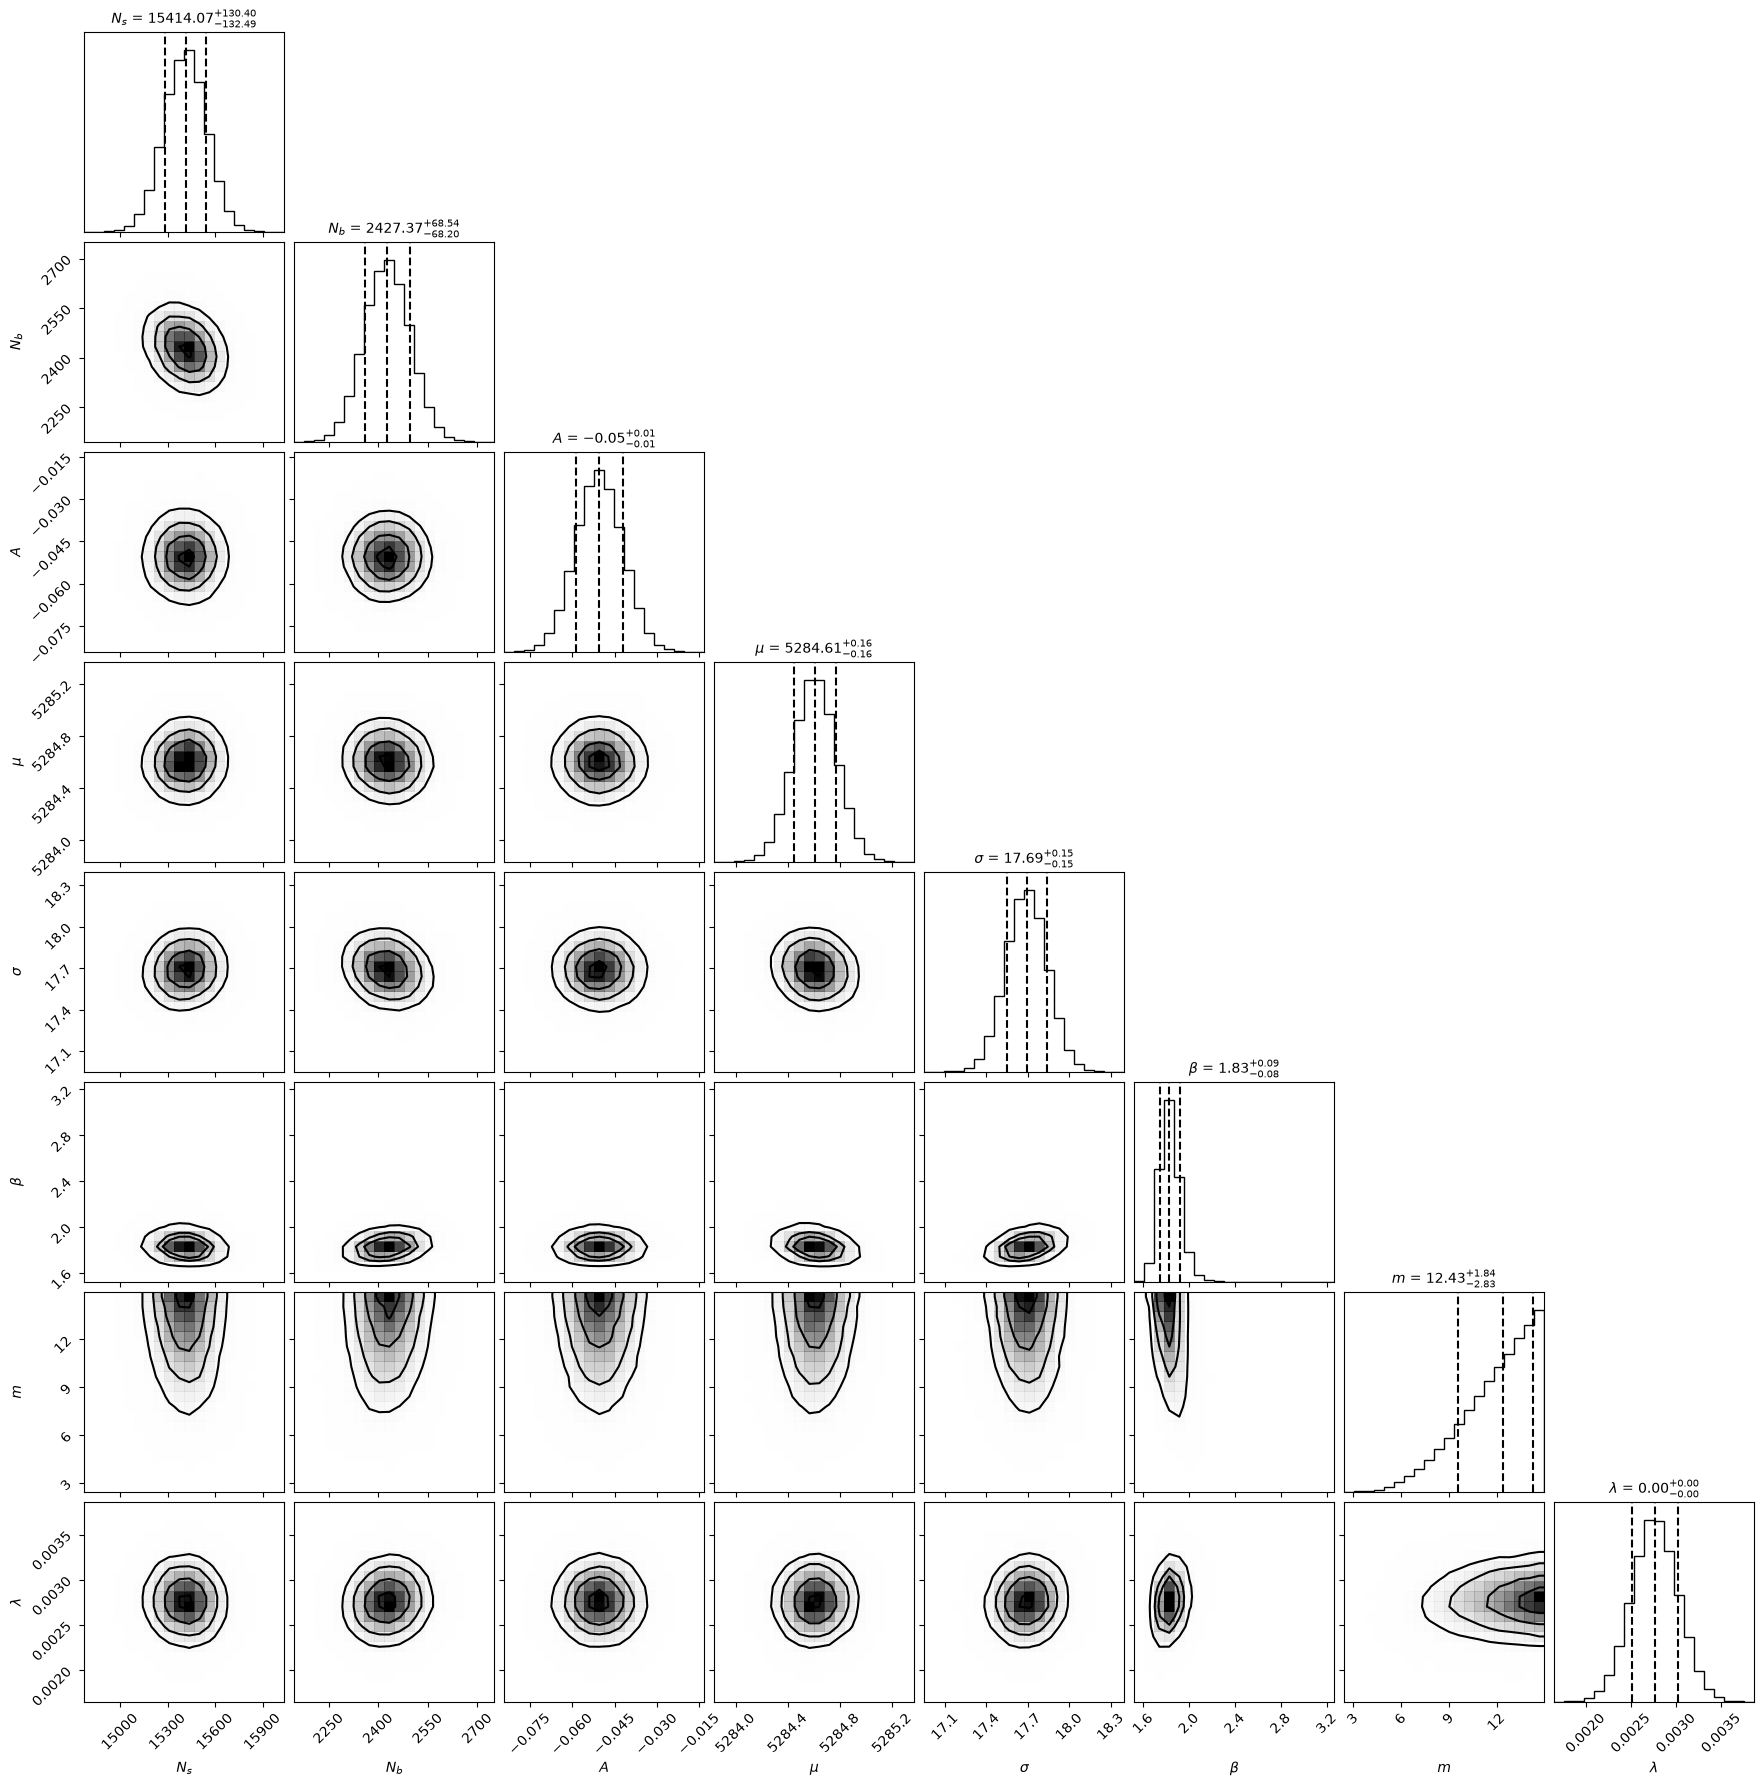

beta fittato = 1.83, m fittato = 12.43 (vs 1.5/3.0 fissati prima)
A_raw (Crystal Ball, beta/m liberi) = -0.0504  68% CI=[-0.0586,-0.0421]
Crystal Ball (beta,m liberi) chi2/ndof = 103.8 / 52 = 2.00
confronto: gaussiana=2.36  CB fissata=4.50  CB libera=2.00
[checkpoint] saved /Users/gmoretti/Work/wt_bayes/LHCb/Code_general/Bayesian/results/crystal_ball_free_checkpoint.json


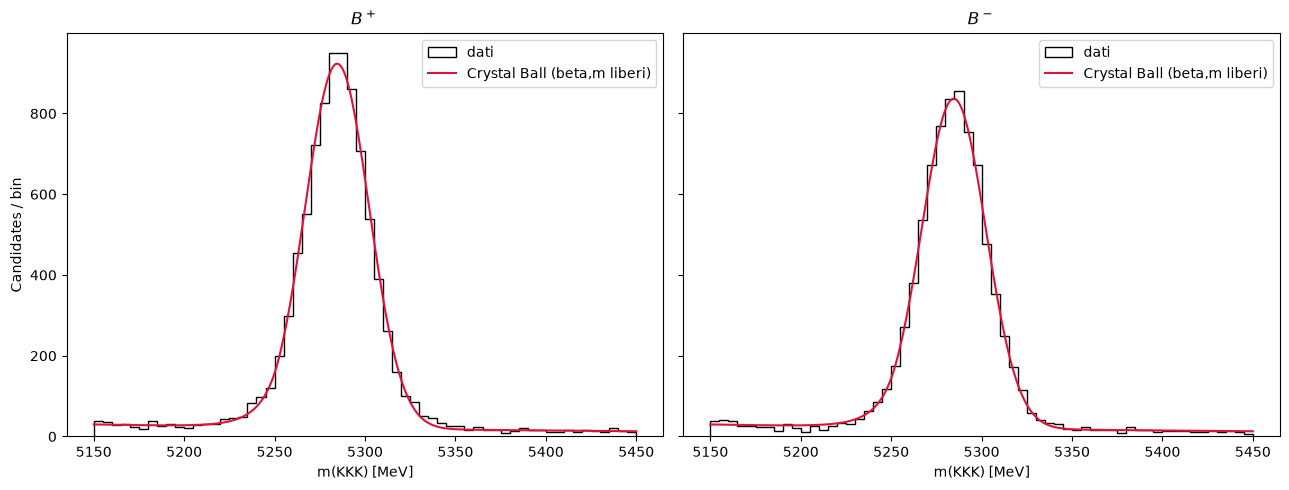

In [30]:
discard_cbf = nsteps_cbf // 6
flat_cbf = sampler_cbf.get_chain(discard=discard_cbf, flat=True)
labels_cbf = [r"$N_s$", r"$N_b$", r"$A$", r"$\mu$", r"$\sigma$", r"$\beta$", r"$m$", r"$\lambda$"]

fig = corner.corner(flat_cbf, labels=labels_cbf, quantiles=[0.16, 0.5, 0.84],
                     show_titles=True, plot_datapoints=False, title_kwargs={"fontsize": 10})
plt.show()

A_cbf = flat_cbf[:, 2]
A_median_cbf = float(np.median(A_cbf))
ci68_cbf = [float(x) for x in np.percentile(A_cbf, [16, 84])]
theta_med_cbf = np.median(flat_cbf, axis=0)
N_s_f, N_b_f, A_f, mu_f, sigma_f, beta_f, m_f, lam_f = theta_med_cbf
print(f"beta fittato = {beta_f:.2f}, m fittato = {m_f:.2f} (vs 1.5/3.0 fissati prima)")
print(f"A_raw (Crystal Ball, beta/m liberi) = {A_median_cbf:.4f}  68% CI=[{ci68_cbf[0]:.4f},{ci68_cbf[1]:.4f}]")

N_s_plus_f, N_s_minus_f, N_b_half_f = N_s_f*(1-A_f)/2, N_s_f*(1+A_f)/2, N_b_f/2

def signal_pdf_cbf(m_, mu_, sigma_, beta_, tail_m_, lo, hi):
    nc = _cb.cdf((hi - mu_) / sigma_, beta_, tail_m_) - _cb.cdf((lo - mu_) / sigma_, beta_, tail_m_)
    return _cb.pdf((m_ - mu_) / sigma_, beta_, tail_m_) / sigma_ / nc

def binned_gof_cbf(m_data, bin_edges, N_s_q, N_b_half_):
    bw = bin_edges[1] - bin_edges[0]
    obs, _ = np.histogram(m_data, bins=bin_edges)
    centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    exp = (N_s_q * signal_pdf_cbf(centers, mu_f, sigma_f, beta_f, m_f, bm.MASS_LO, bm.MASS_HI)
           + N_b_half_ * background_pdf_exp_w(centers, lam_f, bm.MASS_LO, bm.MASS_HI)) * bw
    return np.sum((obs - exp)**2 / np.maximum(exp, 1e-9))

chi2_cbf = (binned_gof_cbf(m_obs[q_obs > 0], gof_bins, N_s_plus_f, N_b_half_f)
            + binned_gof_cbf(m_obs[q_obs < 0], gof_bins, N_s_minus_f, N_b_half_f))
ndof_cbf = 2 * (len(gof_bins) - 1) - ndim_cbf
print(f"Crystal Ball (beta,m liberi) chi2/ndof = {chi2_cbf:.1f} / {ndof_cbf} = {chi2_cbf/ndof_cbf:.2f}")
print(f"confronto: gaussiana={chi2_tot/ndof:.2f}  CB fissata={chi2_cb/ndof:.2f}  CB libera={chi2_cbf/ndof_cbf:.2f}")

checkpoint_save("crystal_ball_free_checkpoint", {
    "A_raw_median": A_median_cbf, "A_raw_ci68": ci68_cbf, "chi2_over_ndof": float(chi2_cbf/ndof_cbf),
    "beta_fitted": float(beta_f), "m_fitted": float(m_f),
})

m_grid_cbf = np.linspace(bm.MASS_LO, bm.MASS_HI, 300)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, q_sign, N_s_q, label in ((axes[0], 1, N_s_plus_f, r"$B^+$"), (axes[1], -1, N_s_minus_f, r"$B^-$")):
    ax.hist(m_obs[q_obs == q_sign], bins=bins, histtype="step", color="k", label="dati")
    curve = (N_s_q * signal_pdf_cbf(m_grid_cbf, mu_f, sigma_f, beta_f, m_f, bm.MASS_LO, bm.MASS_HI)
             + N_b_half_f * background_pdf_exp_w(m_grid_cbf, lam_f, bm.MASS_LO, bm.MASS_HI)) * (bins[1]-bins[0])
    ax.plot(m_grid_cbf, curve, color="crimson", label="Crystal Ball (beta,m liberi)")
    ax.set_xlabel("m(KKK) [MeV]"); ax.set_title(label); ax.legend()
axes[0].set_ylabel("Candidates / bin")
plt.tight_layout()
plt.show()

## Comparison with the published values

Our $A_{raw}$ is corrected neither for the selection efficiency nor for the production and detection asymmetries, so it is not directly comparable with the $A_{CP}$ measured by LHCb; the comparison below is qualitative (same sign, same order of magnitude). The report also compares with the analysis of the same 2011 data (LHCb-PAPER-2013-027).

In [31]:
published_ACP_KKK = -0.037
published_ACP_KKK_err = (0.002**2 + 0.002**2 + 0.003**2)**0.5  # stat (+) syst (+) J/psi K, PRD 108 (2023) 012008

print(f"{'Quantita':<45s}{'Valore':>18s}")
print("-" * 63)
print(f"{'A_raw (nostro, bayesiano, non corretto)':<45s}{A_median:+.4f} [{ci68[0]:+.4f},{ci68[1]:+.4f}]")
print(f"{'A_raw (conteggio grezzo, sanity check)':<45s}{(np.sum(q_obs<0)-np.sum(q_obs>0))/len(q_obs):+.4f}")
print(f"{'A_CP pubblicato (arXiv:2403.19921, KKK)':<45s}{published_ACP_KKK:+.4f} +- {published_ACP_KKK_err:.4f}")
print()
print(f"Stesso segno: {'si' if np.sign(A_median)==np.sign(published_ACP_KKK) else 'no'}.",
      f"Rapporto |nostro/pubblicato| = {abs(A_median/published_ACP_KKK):.2f}",
      "-- ordine di grandezza comparabile, come atteso da una quantita' grezza non corretta.")

Quantita                                                 Valore
---------------------------------------------------------------
A_raw (nostro, bayesiano, non corretto)      -0.0497 [-0.0579,-0.0413]
A_raw (conteggio grezzo, sanity check)       -0.0492
A_CP pubblicato (arXiv:2403.19921, KKK)      -0.0370 +- 0.0041

Stesso segno: si. Rapporto |nostro/pubblicato| = 1.34 -- ordine di grandezza comparabile, come atteso da una quantita' grezza non corretta.


## Dalitz plot and local asymmetries

In this dataset **H1 is always the kaon with charge opposite to the other two** (only the charge combinations (+1,-1,-1) and (-1,+1,+1) exist for (H1,H2,H3)), so H2/H3 are the same-sign pair and are interchangeable: the two invariant masses $m^2(H1,H2)$ and $m^2(H1,H3)$ are ordered (`m2_lo`, `m2_hi`) to remove this labelling ambiguity.

In [32]:
charges_arr = data[["H1_Charge", "H2_Charge", "H3_Charge"]].to_numpy()
Bc_arr = data["B_Charge"].to_numpy()
is_bachelor = charges_arr != np.sign(Bc_arr)[:, None]
assert np.all(is_bachelor.sum(axis=1) == 1), "atteso esattamente un bachelor per evento"
bach_idx = np.argmax(is_bachelor, axis=1)
same_idx = np.array([[j for j in range(3) if j != b] for b in bach_idx])

E_cols = data[["H1_E", "H2_E", "H3_E"]].to_numpy()
Px_cols = data[["H1_PX", "H2_PX", "H3_PX"]].to_numpy()
Py_cols = data[["H1_PY", "H2_PY", "H3_PY"]].to_numpy()
Pz_cols = data[["H1_PZ", "H2_PZ", "H3_PZ"]].to_numpy()
rows = np.arange(len(data))

def pair_m2(i_idx, j_idx):
    E = E_cols[rows, i_idx] + E_cols[rows, j_idx]
    Px = Px_cols[rows, i_idx] + Px_cols[rows, j_idx]
    Py = Py_cols[rows, i_idx] + Py_cols[rows, j_idx]
    Pz = Pz_cols[rows, i_idx] + Pz_cols[rows, j_idx]
    return (E**2 - (Px**2 + Py**2 + Pz**2)) / 1e6  # GeV^2

m2_a = pair_m2(bach_idx, same_idx[:, 0])
m2_b = pair_m2(bach_idx, same_idx[:, 1])
m2_lo_dz = np.minimum(m2_a, m2_b)
m2_hi_dz = np.maximum(m2_a, m2_b)

q_dz = data["B_Charge"].to_numpy()
print(f"m2_lo range: [{m2_lo_dz.min():.2f}, {m2_lo_dz.max():.2f}] GeV^2")
print(f"m2_hi range: [{m2_hi_dz.min():.2f}, {m2_hi_dz.max():.2f}] GeV^2")

m2_lo range: [0.98, 14.29] GeV^2
m2_hi range: [2.86, 24.01] GeV^2


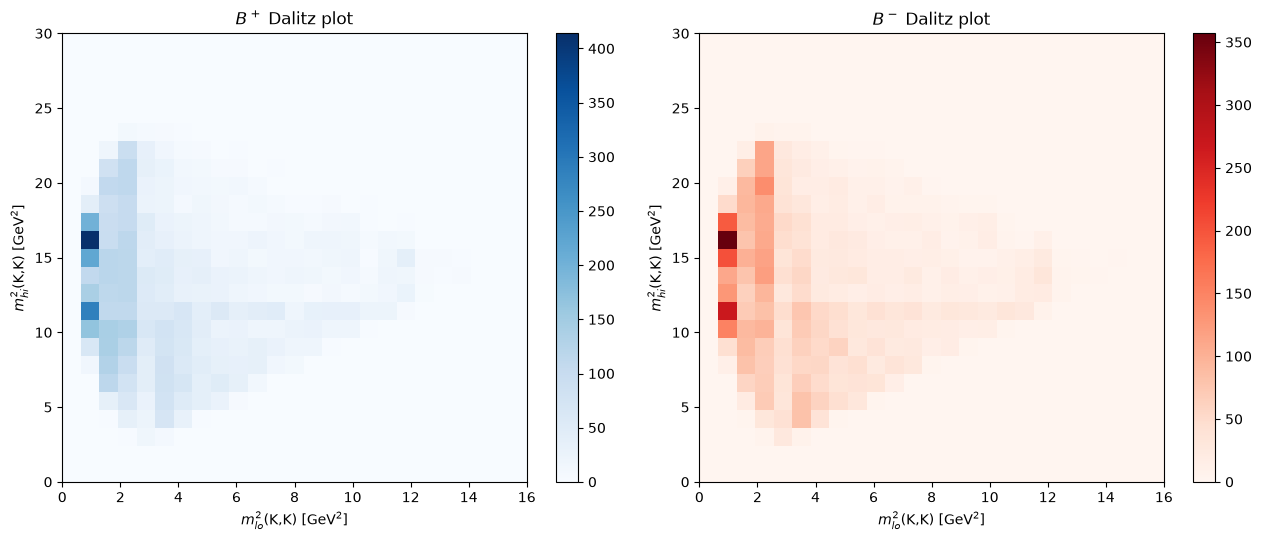

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
dz_range = [[0, 16], [0, 30]]
h_p = axes[0].hist2d(m2_lo_dz[q_dz > 0], m2_hi_dz[q_dz > 0], bins=25, range=dz_range, cmap="Blues")
axes[0].set_title(r"$B^+$ Dalitz plot")
h_m = axes[1].hist2d(m2_lo_dz[q_dz < 0], m2_hi_dz[q_dz < 0], bins=25, range=dz_range, cmap="Reds")
axes[1].set_title(r"$B^-$ Dalitz plot")
for ax, h in zip(axes, (h_p, h_m)):
    ax.set_xlabel(r"$m^2_{lo}$(K,K) [GeV$^2$]")
    ax.set_ylabel(r"$m^2_{hi}$(K,K) [GeV$^2$]")
    plt.colorbar(h[3], ax=ax)
plt.tight_layout()
plt.show()

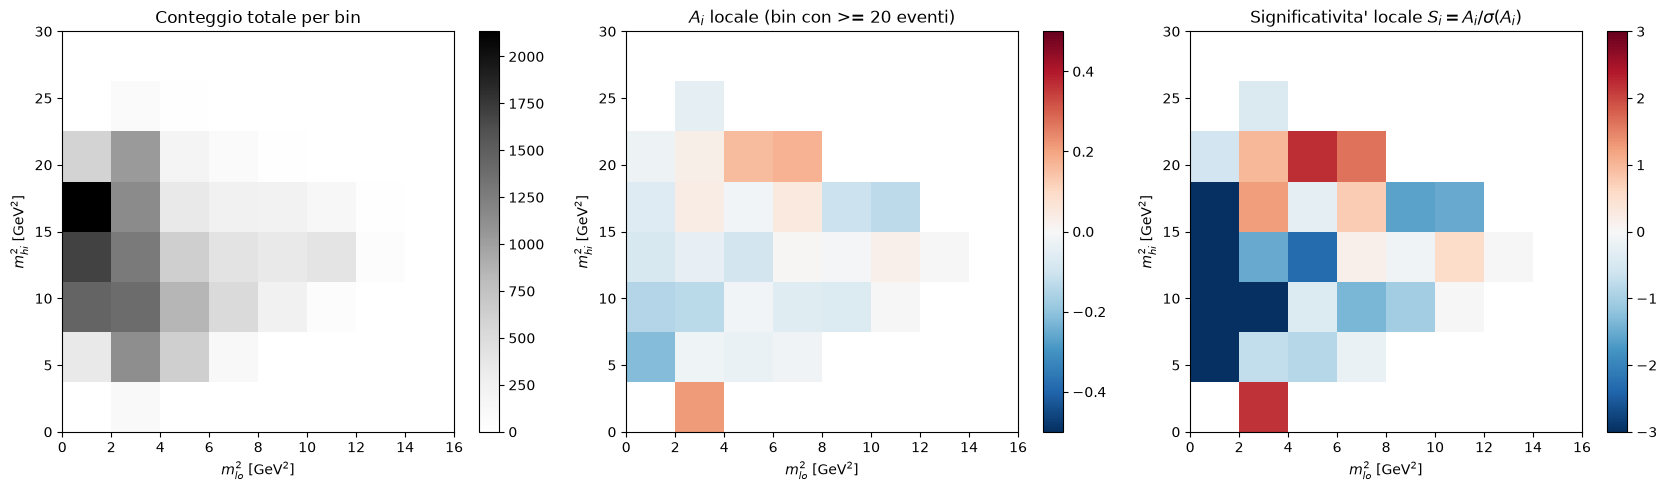

bin con |S_i| > 3 (potenzialmente interessanti): 4 su 29 bin popolati
rispetto ad A_glob=-0.0492: 3 bin con |S_i|>3; omogeneita' chi2=85.6/28, p=9.6e-08


In [34]:
nbins_dz = 8
edges_lo = np.linspace(dz_range[0][0], dz_range[0][1], nbins_dz + 1)
edges_hi = np.linspace(dz_range[1][0], dz_range[1][1], nbins_dz + 1)

N_plus, _, _ = np.histogram2d(m2_lo_dz[q_dz > 0], m2_hi_dz[q_dz > 0], bins=[edges_lo, edges_hi])
N_minus, _, _ = np.histogram2d(m2_lo_dz[q_dz < 0], m2_hi_dz[q_dz < 0], bins=[edges_lo, edges_hi])

N_tot = N_plus + N_minus
with np.errstate(divide="ignore", invalid="ignore"):
    A_local = np.where(N_tot > 0, (N_minus - N_plus) / N_tot, np.nan)
    sigma_A_local = np.where(N_tot > 0, np.sqrt(np.maximum(1 - A_local**2, 0) / N_tot), np.nan)
    S_local = np.where(sigma_A_local > 0, A_local / sigma_A_local, np.nan)

min_events_per_bin = 20
A_local_masked = np.where(N_tot >= min_events_per_bin, A_local, np.nan)
S_local_masked = np.where(N_tot >= min_events_per_bin, S_local, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
im0 = axes[0].imshow(N_tot.T, origin="lower", aspect="auto",
                      extent=[*dz_range[0], *dz_range[1]], cmap="Greys")
axes[0].set_title("Conteggio totale per bin"); plt.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(A_local_masked.T, origin="lower", aspect="auto",
                      extent=[*dz_range[0], *dz_range[1]], cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[1].set_title(f"$A_i$ locale (bin con >= {min_events_per_bin} eventi)"); plt.colorbar(im1, ax=axes[1])
im2 = axes[2].imshow(S_local_masked.T, origin="lower", aspect="auto",
                      extent=[*dz_range[0], *dz_range[1]], cmap="RdBu_r", vmin=-3, vmax=3)
axes[2].set_title("Significativita' locale $S_i = A_i/\\sigma(A_i)$"); plt.colorbar(im2, ax=axes[2])
for ax in axes:
    ax.set_xlabel(r"$m^2_{lo}$ [GeV$^2$]"); ax.set_ylabel(r"$m^2_{hi}$ [GeV$^2$]")
plt.tight_layout()
plt.show()

n_significant = np.sum(np.abs(S_local_masked) > 3)
print(f"bin con |S_i| > 3 (potenzialmente interessanti): {n_significant} su {np.sum(N_tot >= min_events_per_bin)} bin popolati")

# significance with respect to the GLOBAL asymmetry (the test against zero above partly reflects A_glob itself)
A_glob_dz = (np.sum(q_dz < 0) - np.sum(q_dz > 0)) / len(q_dz)
pop = N_tot >= min_events_per_bin
S_glob = (A_local[pop] - A_glob_dz) / sigma_A_local[pop]
n_significant_glob = int(np.sum(np.abs(S_glob) > 3))
chi2_hom = float(np.sum(S_glob**2)); ndof_hom = int(pop.sum() - 1)
from scipy.stats import chi2 as _chi2_dz
p_hom = float(_chi2_dz.sf(chi2_hom, ndof_hom))
print(f"rispetto ad A_glob={A_glob_dz:.4f}: {n_significant_glob} bin con |S_i|>3; "
      f"omogeneita' chi2={chi2_hom:.1f}/{ndof_hom}, p={p_hom:.1e}")

### Local Dalitz asymmetry in the signal window (less background)

The map above uses *all* candidates in the fit window [5150,5450] MeV, background included. Here the sample is restricted to $|m - \mu| < 2\sigma$ (~5253-5313 MeV, signal purity >95%) for a comparison with less background -- not a proper background subtraction, but a tighter cut that strongly reduces the background contribution.

eventi in |m-mu|<2*sigma: 15119 (vs 17839 nella finestra di fit completa)


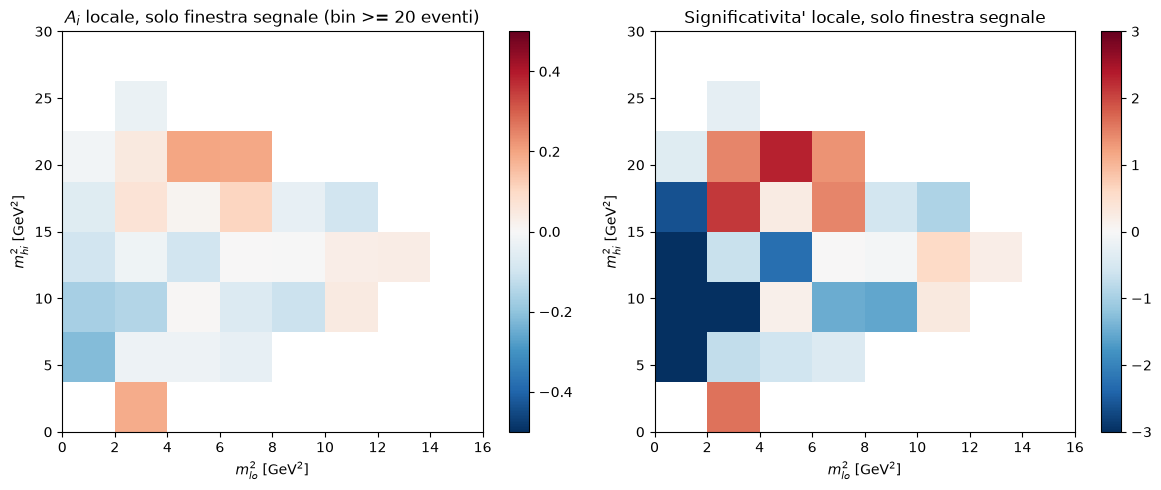

finestra segnale: 29 bin popolati, 4 con |S_i|>3 -- confronta con 29/4 della mappa a finestra piena
finestra segnale, rispetto ad A_glob=-0.0460: 3 bin con |S_i|>3; omogeneita' chi2=95.5/28


In [35]:
sig_window_mask = np.abs(m_obs - mu) < 2 * sigma
m2_lo_sig = m2_lo_dz[sig_window_mask]
m2_hi_sig = m2_hi_dz[sig_window_mask]
q_sig = q_dz[sig_window_mask]
print(f"eventi in |m-mu|<2*sigma: {sig_window_mask.sum()} (vs {len(m_obs)} nella finestra di fit completa)")

N_plus_sig, _, _ = np.histogram2d(m2_lo_sig[q_sig > 0], m2_hi_sig[q_sig > 0], bins=[edges_lo, edges_hi])
N_minus_sig, _, _ = np.histogram2d(m2_lo_sig[q_sig < 0], m2_hi_sig[q_sig < 0], bins=[edges_lo, edges_hi])
N_tot_sig = N_plus_sig + N_minus_sig

with np.errstate(divide="ignore", invalid="ignore"):
    A_local_sig = np.where(N_tot_sig > 0, (N_minus_sig - N_plus_sig) / N_tot_sig, np.nan)
    sigma_A_sig = np.where(N_tot_sig > 0, np.sqrt(np.maximum(1 - A_local_sig**2, 0) / N_tot_sig), np.nan)
    S_local_sig = np.where(sigma_A_sig > 0, A_local_sig / sigma_A_sig, np.nan)

min_events_sig = 20  # same threshold as the full-window map
A_local_sig_masked = np.where(N_tot_sig >= min_events_sig, A_local_sig, np.nan)
S_local_sig_masked = np.where(N_tot_sig >= min_events_sig, S_local_sig, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(A_local_sig_masked.T, origin="lower", aspect="auto",
                      extent=[*dz_range[0], *dz_range[1]], cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[0].set_title(f"$A_i$ locale, solo finestra segnale (bin >= {min_events_sig} eventi)")
plt.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(S_local_sig_masked.T, origin="lower", aspect="auto",
                      extent=[*dz_range[0], *dz_range[1]], cmap="RdBu_r", vmin=-3, vmax=3)
axes[1].set_title("Significativita' locale, solo finestra segnale")
plt.colorbar(im1, ax=axes[1])
for ax in axes:
    ax.set_xlabel(r"$m^2_{lo}$ [GeV$^2$]"); ax.set_ylabel(r"$m^2_{hi}$ [GeV$^2$]")
plt.tight_layout()
plt.show()

n_pop_sig = int(np.sum(N_tot_sig >= min_events_sig))
n_sig_sig = int(np.sum(np.abs(S_local_sig_masked) > 3))
print(f"finestra segnale: {n_pop_sig} bin popolati, {n_sig_sig} con |S_i|>3 -- confronta con {int(np.sum(N_tot >= min_events_per_bin))}/{n_significant} della mappa a finestra piena")

A_glob_sig = (np.sum(q_sig < 0) - np.sum(q_sig > 0)) / len(q_sig)
pop_sig = N_tot_sig >= min_events_sig
S_glob_sig = (A_local_sig[pop_sig] - A_glob_sig) / sigma_A_sig[pop_sig]
n_sig_glob_sig = int(np.sum(np.abs(S_glob_sig) > 3))
chi2_hom_sig = float(np.sum(S_glob_sig**2)); ndof_hom_sig = int(pop_sig.sum() - 1)
print(f"finestra segnale, rispetto ad A_glob={A_glob_sig:.4f}: {n_sig_glob_sig} bin con |S_i|>3; "
      f"omogeneita' chi2={chi2_hom_sig:.1f}/{ndof_hom_sig}")

## Save the results

Saved in `results/` so that later comparisons do not need to rerun the MCMC.

In [36]:
np.savez(os.path.join(RESULTS_DIR, "mcmc_chain.npz"), chain=sampler.get_chain(), flat_samples=flat_samples,
         discard=discard, param_names=bm.PARAM_NAMES)

summary = {
    "sideband_symmetry_checkpoint": {"mu_post": float(mu_post), "sigma_post": float(sigma_post),
                                    "n_sideband": n_tot_sb, "n_plus": n_plus_sb, "n_minus": n_minus_sb,
                                    "A_sideband": float(A_sb), "sigma_A_sideband": float(sigma_A_sb)},
    "n_events_fit_window": int(len(m_obs)),
    "mass_window_MeV": [bm.MASS_LO, bm.MASS_HI],
    "A_raw_median": float(A_median),
    "A_raw_ci68": [float(ci68[0]), float(ci68[1])],
    "A_raw_ci95": [float(ci95[0]), float(ci95[1])],
    "bayes_factor_A0_vs_Afree": float(BF_01),
    "bayes_factor_gaussian_approx": float(BF_01_gauss),
    "bayes_factor_bandwidth_sensitivity": {f"x{m}": float(b) for m, b in zip(bw_multipliers, bf_vs_bw)},
    "mean_acceptance_fraction": float(np.mean(sampler.acceptance_fraction)),
    "nwalkers": nwalkers, "nsteps": nsteps, "discard": discard,
    "magnet_down": {"n": result_down["n"], "A_median": result_down["A_median"], "A_ci68": result_down["A_ci68"]},
    "magnet_up": {"n": result_up["n"], "A_median": result_up["A_median"], "A_ci68": result_up["A_ci68"]},
    "toy_mc_coverage": {
        "n_toys": N_TOYS, "nsteps_toy": NSTEPS_TOY,
        "empirical_coverage_68": cov68_frac, "empirical_coverage_95": cov95_frac,
        "nominal_68": 0.68, "nominal_95": 0.95,
    },
    "systematic_variations": syst_results,
    "free_background_asymmetry": free_bkg_summary,
    "dispersed_start_runs": dispersed_summary,
    "charm_vetoes": charm_veto_summary,
    "toy_mc_estimates": {"bias": toy_bias, "bias_err": toy_bias_err, "sd": toy_sd, "posterior_sd_data": float(np.std(A_samples))},
    "goodness_of_fit": {"chi2_total": float(chi2_tot), "ndof": int(ndof), "chi2_over_ndof": float(chi2_tot/ndof)},
    "goodness_of_fit_crystal_ball": {"A_raw_median": A_median_cb, "A_raw_ci68": ci68_cb,
                                      "chi2_over_ndof": float(chi2_cb/ndof), "beta_fixed": CB_BETA, "m_fixed": CB_M},
    "goodness_of_fit_crystal_ball_free": {"A_raw_median": A_median_cbf, "A_raw_ci68": ci68_cbf,
                                           "chi2_over_ndof": float(chi2_cbf/ndof_cbf),
                                           "beta_fitted": float(beta_f), "m_fitted": float(m_f),
                                           "nwalkers": nwalkers_cbf, "nsteps": nsteps_cbf},
    "published_comparison": {"A_CP_published_KKK": published_ACP_KKK, "A_CP_published_err": published_ACP_KKK_err},
    "dalitz_local_asymmetry": {"n_bins_populated": int(np.sum(N_tot >= min_events_per_bin)),
                                "n_bins_significant_3sigma": int(n_significant),
                                "A_glob": float(A_glob_dz), "n_bins_significant_3sigma_vs_global": n_significant_glob,
                                "chi2_homogeneity": chi2_hom, "ndof_homogeneity": ndof_hom, "p_homogeneity": p_hom},
    "dalitz_local_asymmetry_signal_window": {"n_events": int(sig_window_mask.sum()),
                                              "n_bins_populated": n_pop_sig, "n_bins_significant_3sigma": n_sig_sig,
                                              "n_bins_significant_3sigma_vs_global": n_sig_glob_sig,
                                              "chi2_homogeneity": chi2_hom_sig, "ndof_homogeneity": ndof_hom_sig},
}
with open(os.path.join(RESULTS_DIR, "posterior_summary.json"), "w") as f:
    _json.dump(summary, f, indent=2)

print(_json.dumps(summary, indent=2))

{
  "sideband_symmetry_checkpoint": {
    "mu_post": 5284.409866809464,
    "sigma_post": 17.948108073420144,
    "n_sideband": 1217,
    "n_plus": 637,
    "n_minus": 580,
    "A_sideband": -0.04683648315529992,
    "sigma_A_sideband": 0.028633724447151496
  },
  "n_events_fit_window": 17839,
  "mass_window_MeV": [
    5150.0,
    5450.0
  ],
  "A_raw_median": -0.04972502482826961,
  "A_raw_ci68": [
    -0.05787008000900426,
    -0.04134353011281907
  ],
  "A_raw_ci95": [
    -0.06591755855055995,
    -0.03309108295283332
  ],
  "bayes_factor_A0_vs_Afree": 3.213500282495621e-59,
  "bayes_factor_gaussian_approx": 2.062920785414646e-06,
  "bayes_factor_bandwidth_sensitivity": {
    "x0.5": 2.499538538341949e-228,
    "x1.0": 3.213500282495621e-59,
    "x1.5": 5.048202943988181e-28,
    "x2.0": 3.6181408774644504e-17,
    "x3.0": 1.6807230040420198e-09
  },
  "mean_acceptance_fraction": 0.5170868055555555,
  "nwalkers": 32,
  "nsteps": 9000,
  "discard": 1500,
  "magnet_down": {
    "n":

## Known limitations

- **Charge-symmetric background** ($N_b/2$, $N_b/2$): the fit with free background asymmetry gives $A_b=-0.071\pm0.024$ and moves $A_{raw}$ by $+0.004$; the nominal model of `Bayesian_Nominal.ipynb` leaves $A_b$ free.
- **Bayes factor via Savage-Dickey**: the KDE value varies by many orders of magnitude with the bandwidth (A=0 is far in the tail); the Gaussian approximation is used, and only the qualitative conclusion (decisive evidence against A=0) is robust.
- **Toy-MC coverage**: with 500 replicas (3500 steps) the empirical 68% coverage is 0.664 (nominal 0.68, 0.77 sigma) and the 95% coverage 0.962 (nominal 0.95): consistent with nominal.
- **Goodness of fit**: the pure Gaussian does not describe the data well ($\chi^2$/ndof = 2.36); the Crystal Ball with free $\beta,m$ improves it to 2.00 ($\beta=1.83$, $m=12.4$) without moving $A_{raw}$.
- **Dalitz plot**: coarse 8x8 binning, no background subtraction; the signal-window version reduces but does not remove the background.
